# Примена SVD


Садржај:
1. [Проблеми високе димензионалности података](#Проблеми-високе-димензионалности-података)
1. [Апроксимација матрица](#Апроксимација-матрица)
1. [Анализа главних компоненти (PCA)](#Анализа-главних-компоненти-(PCA))

In [1]:
import numpy as np
import numpy.random as rndm
import scipy.linalg as spl
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

Наредне кодне ћелије активирати уколико је потребна инсталација наведених модула или апдејт, тј. ако их нисте претходно већ инсталирали.

In [ ]:
pip install --upgrade notebook

In [ ]:
pip install paramiko --upgrade

In [ ]:
pip install tensorflow

In [ ]:
pip install tensorflow_datasets

## Проблеми високе димензионалности података

Наша чула подешена су да видимо свет око нас у три димензије. Збг тога се суочавамо са проблемом када покушамо да замислимо простор са више димензија. Чак и обична коцка у 4D (хиперкоцка) је веома тешка да се визуелно усвоји, а камоли $200$-димензионални елипсоид угњежден у потпростор димензије пар хиљада. 

<div>
   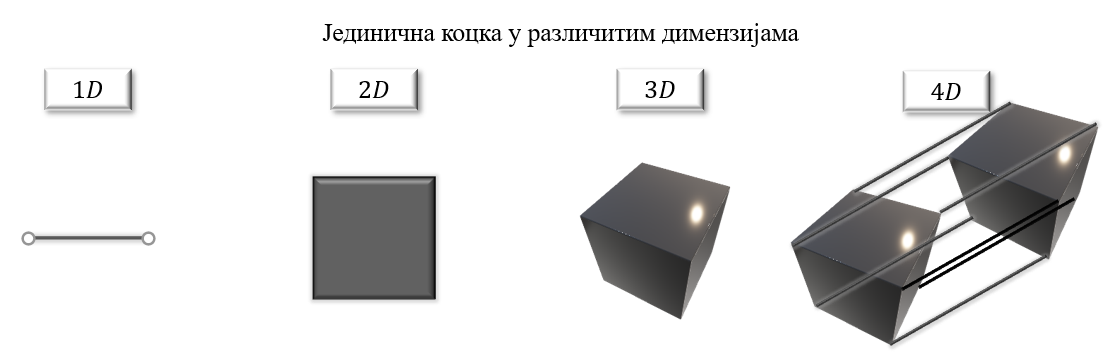  
</div>

Осим интуитивних потешкоћа, са повећањем димензионалности објекти губе својства на која смо навикли у 2D и 3D геометрији.Овај феномен је познат као **Клетва димензионалности** (Curse of Dimensionality). Приказаћемо то кроз наредне примере.

**Пример 1.** Празнина унутрашњости и концентрација на границама

Посматраћемо јединичну хиперкоцку $[0,1]^n.$ Тачка из хиперкоцке се сматра "екстремном" (на граници) ако је бар једна њена координата веома близу 0 или 1 (нпр. на удаљености мањој од 0.01).Генерисаћемо по $1000$ случајних тачака унутар јединичне коцке простора различитих димензија. То ће значити да се координате тачака бирају униформно из сегмента $[0,1]$ и да избор координата сваке од тачака није никако повезан - независан избор случајних бројева. Бројаћемо тачке које се налазе близу граница јединичне коцке, тј пратићемо појаву "екстремних" тачака дуж било које координатне осе. 

У једнодимензионалном простору јединичну коцку представља сегмент $[0,1].$ Генерисаћемо тачке унутар ове коцке коришћењем модула Random. То ће значити генерисање само једне координате за $1000$ тачака.

In [2]:
tacke1=rndm.rand(1000)
k1=np.sum((tacke1<0.01) | (tacke1>0.99))
k1

18

Експеримент можемо да поновимо више пута како бисмо добили процену просечног броја појављивања оваквих тачака рачунањем средње вредности.

In [3]:
k1=0
for i in range(499):
    tacke1=rndm.rand(1000)
    k1+=np.sum((tacke1<0.01) | (tacke1>0.99))
prosek1=k1/500    
print("prosek ekstremnih tacaka=",prosek1)    
print("u procentima =",np.round(prosek1/10,2))

prosek ekstremnih tacaka= 19.806
u procentima = 1.98


Примећујемо да је проценат екстремних тачака око $2\%.$

У дводимензионалном случају јединичну коцку представља јединични квадрат $[0,1]\times[0,1].$ Генерисаћемо $1000$ случајних тачака овог скупа, тј. дводимезионални низ типа $2\times1000.$  

In [4]:
tacke2=rndm.rand(2,1000)
k2=np.sum(np.any((tacke2<0.01) | (tacke2>0.99), axis=0))
k2

47

Понављањем експеримента добијамо просечан број појављивања оваквих ивичних тачака.

In [5]:
k2=0
for i in range(500):
    tacke2=rndm.rand(2,1000)
    k2+=np.sum(np.any((tacke2<0.01) | (tacke2>0.99), axis=0))
prosek2=k2/500    
print("prosek ekstremnih tacaka=",prosek2) 
print("u procentima =",np.round(prosek2/10,2))

prosek ekstremnih tacaka= 39.75
u procentima = 3.98


Са повећањем димензије за $1$ број екстрема је порасао на око $4\%.$

На сличан начин регистроваћемо појављивање екстрема у јединичној коцки за просторе димензије $n\in\{3,10,100,1000,10000\}.$

In [6]:
for n in [3,10,100,1000,10000]:
    k=0
    for i in range(500):
        tacke=rndm.rand(n,1000)
        k+=np.sum(np.any((tacke<0.01) | (tacke>0.99), axis=0))
    prosek=k/500
    print("Za n=",n, "prosek ekstremnih tacaka=",prosek)
    print("u procentima=",np.round(prosek/10,2))

Za n= 3 prosek ekstremnih tacaka= 58.978
u procentima= 5.9
Za n= 10 prosek ekstremnih tacaka= 182.372
u procentima= 18.24
Za n= 100 prosek ekstremnih tacaka= 867.62
u procentima= 86.76
Za n= 1000 prosek ekstremnih tacaka= 1000.0
u procentima= 100.0
Za n= 10000 prosek ekstremnih tacaka= 1000.0
u procentima= 100.0


Пример показује да са великим бројем димензија готово све тачке јединичне коцке спадају у екстреме дуж неке координатне осе у случају равномерне расподеле вредности координата. Због тога је одбацивање података са екстремним вредностима (outlier) у више димензија губитак суштинских информација.

**Закључак:** У високим димензијама, унутрашњост јединичне хиперкоцке је скоро потпуно празна. Готово сви подаци се налазе уз саму ивицу простора. Ово значи да су аутлајери у високодимензионалним просторима заправо правило, а не изузетак.

Претходно запажање потврдићемо кроз тачке хиперсфере унутар хиперкоцке. 
Размотримо јединичну хиперкоцку димензије \(n\) (чија је запремина увек \(1^n = 1\))
и уписану хиперсферу полупречника \(r = 0.5\) која се налази у њеном центру.

Колики део узорака коцке се налази у сфери?

In [8]:
def odnos_uzoraka(n, broj_uzoraka=100000):
    # Generisemo tacke u prostoru [-0.5, 0.5]^n
    tacke = rndm.uniform(-0.5, 0.5, (broj_uzoraka, n))
    # Tacka je unutar sfere ako je njena norma <= 0.5
    norme = np.linalg.norm(tacke, axis=1)
    unutar_sfere = np.sum(norme <= 0.5)
    return unutar_sfere / broj_uzoraka

for n in [2, 3, 5, 10, 15, 20]:
    procenat = odnos_uzoraka(n)
    print(f"n = {n:2d} | Uzorci iz sfere zauzimaju {procenat*100:7.4f}% ")

n =  2 | Uzorci iz sfere zauzimaju 78.6190% 
n =  3 | Uzorci iz sfere zauzimaju 52.1020% 
n =  5 | Uzorci iz sfere zauzimaju 16.5480% 
n = 10 | Uzorci iz sfere zauzimaju  0.2490% 
n = 15 | Uzorci iz sfere zauzimaju  0.0010% 
n = 20 | Uzorci iz sfere zauzimaju  0.0000% 


***

**Пример 2.** Концентрација растојања

Бираћемо парове тачака унутар јединичне коцке и мерићемо растојање међу њима. Пратићемо расподелу ових растојања за различите димензије простора. 

In [9]:
for n in [1,2,3,10,100,1000,10000,1000000]:
    d=0
    for i in range(500):
        tacke=rndm.rand(2,n)
        d+=np.linalg.norm(tacke[0]-tacke[1])
    print("Za n=",n, "prosecno rastojanje=",d/500)

Za n= 1 prosecno rastojanje= 0.3323371868412523
Za n= 2 prosecno rastojanje= 0.5203437707874181
Za n= 3 prosecno rastojanje= 0.6468689609795196
Za n= 10 prosecno rastojanje= 1.2612206270538222
Za n= 100 prosecno rastojanje= 4.088030469714409
Za n= 1000 prosecno rastojanje= 12.906781287041007
Za n= 10000 prosecno rastojanje= 40.808765959940104
Za n= 1000000 prosecno rastojanje= 408.25794509853284


Како димензија расте, Еуклидско растојање између било које две случајне тачке се концентрише око једне вредности. Разлика између "најближег" и "најдаљег" суседа постаје занемарљива.

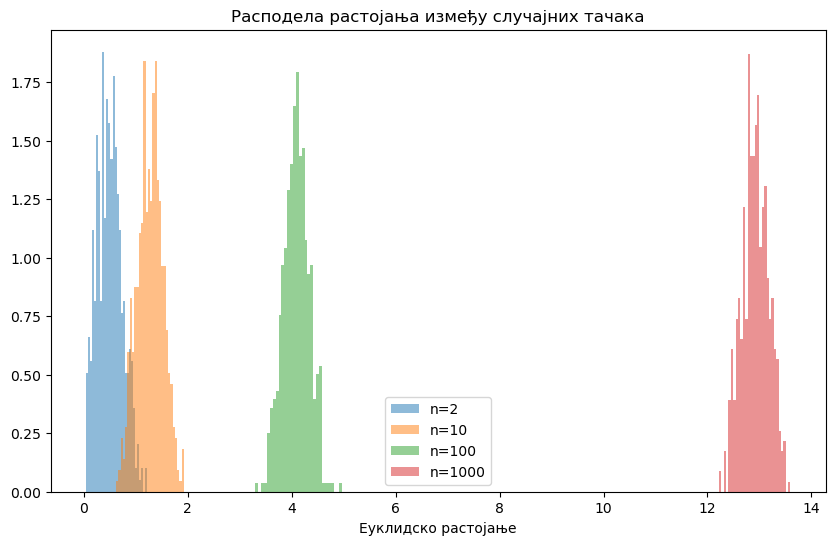

In [10]:
def uporedi_rastojanja(dimenzije, N=1000):
    plt.figure(figsize=(10, 6))
    for n in dimenzije:
        tacke = rndm.rand(N, n)
        # Racunamo rastojanja izmedju prvih 500 parova tacaka radi brzine
        dist = np.linalg.norm(tacke[:500] - tacke[500:], axis=1)
        plt.hist(dist, bins=30, alpha=0.5, label=f'n={n}', density=True)
    
    plt.title("Расподела растојања између случајних тачака")
    plt.xlabel("Еуклидско растојање")
    plt.legend()
    plt.show()

uporedi_rastojanja([2, 10, 100, 1000])

Шта ово значи за ML? Алгоритми засновани на растојању (као што су k-NN или кластеризација) губи своју дискриминаторну моћ у високим димензијама јер су скоро све тачке "подједнако далеко".

***

**Пример 3.** Ортогоналност и разређење простора

У ниским димензијама, вектори заузимају широк спектар углова. У високим димензијама, два случајна вектора су скоро увек међусобно ортогонална.
Посматраћемо утицај повећања димензије векторског простора на угао између вектора $\mathbb{1}_n\in\mathbb{R}^n$ и вектора канонске базе $\{e_1,e_2,\dots.e_n\}$ простора $\mathbb{R}^n:$
$$\mathbb{1}_n=\begin{bmatrix}1&1&\dots&1\end{bmatrix}^T$$

$$\cos\angle(\mathbb{1}_{n},e_k)=\dfrac{\mathbb{1}_{n}\cdot e_k}{\|\mathbb{1}_{n}\|\,\|e_k\|}=\dfrac{1}{\sqrt{n}}$$

а) У простору $\mathbb{R}^2,$ посматрано у односу на Декартов координатни систем, линија која полови први квадрант тј. вектор $\mathbb{1}_2=\begin{bmatrix}1&1\end{bmatrix}^T$ гради углове од $45^o$ са сваком од координатних оса. Координатне осе одређене су канонском базом
$$e_1=\begin{bmatrix}1&0\end{bmatrix}^T,\qquad e_2=\begin{bmatrix}0&1\end{bmatrix}^T.$$
<div>
   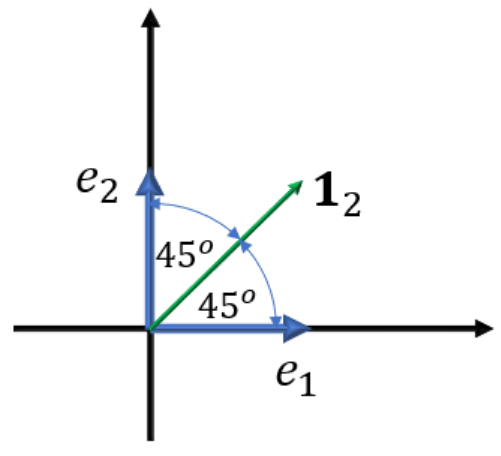  
</div>
Показаћемо ово тврђење израчунавањем косинуса углова.

In [11]:
kosugla=1/np.sqrt(2)
np.arccos(kosugla)   #ugao u radijanima

0.7853981633974484

In [12]:
np.arccos(kosugla)*180/np.pi   #ugao u stepenima

45.00000000000001

б) У простору $\mathbb{R}^3$ које углове заклапа вектор $\mathbb{1}_3=\begin{bmatrix}1&1&1\end{bmatrix}^T$ са сваким од вектора канонске базе $$e_1=\begin{bmatrix}1&0&0\end{bmatrix}^T,\qquad e_2=\begin{bmatrix}0&1&0\end{bmatrix}^T,\qquad e_3=\begin{bmatrix}0&0&1\end{bmatrix}^T?$$
Приметимо да вектор $\mathbb{1}_3$ представља дијагонални вектор првог октанта.
<div>
   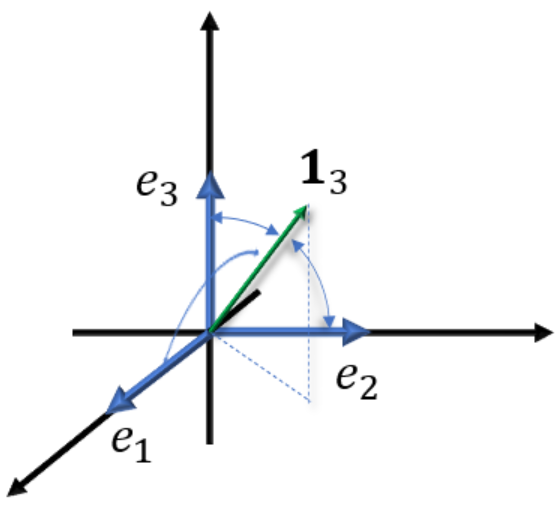  
</div>

In [13]:
kosugla=1/np.sqrt(3)
np.arccos(kosugla) #ugao u radijanima

0.9553166181245092

In [14]:
np.arccos(kosugla)*180/np.pi  #ugao u stepenima

54.735610317245346

в) Колико ће износити углови између вектора  $\mathbb{1}_{10}\in\mathbb{R}^{10}$ и вектора канонске базе $\{e_1,e_2,\dots,e_{10}\}?$ Колико ће такви углови износити за димензије $n=100$ и $n=1000?$ Шта ће се догодити ако наставимо да повећавамо димензију простора?

$n=10:\quad$ $\cos\angle(\mathbb{1}_{10},e_k)=\dfrac{\mathbb{1}_{10}\cdot e_k}{\|\mathbb{1}_{10}\|\,\|e_k\|}=\dfrac{1}{\sqrt{10}}$

In [15]:
kosugla=1/np.sqrt(10)
np.arccos(kosugla)

1.2490457723982544

In [16]:
np.arccos(kosugla)*180/np.pi

71.56505117707799

$n=100:\quad$ $\cos\angle(\mathbb{1}_{100},e_k)=\dfrac{\mathbb{1}_{100}\cdot e_k}{\|\mathbb{1}_{100}\|\,\|e_k\|}=\dfrac{1}{\sqrt{100}}$

In [17]:
kosugla=1/np.sqrt(100)
np.arccos(kosugla)

1.4706289056333368

In [18]:
np.arccos(kosugla)*180/np.pi

84.26082952273322

$n=1000:\quad$ $\cos\angle(\mathbb{1}_{1000},e_k)=\dfrac{\mathbb{1}_{1000}\cdot e_k}{\|\mathbb{1}_{1000}\|\,\|e_k\|}=\dfrac{1}{\sqrt{1000}}$

In [19]:
kosugla=1/np.sqrt(1000)
np.arccos(kosugla)

1.539168277357325

In [20]:
np.arccos(kosugla)*180/np.pi

88.18784625299604

Закључујемо да са порастом димензије косинус угла између посматарних вектора тежи нули. То значи да вредност угла тежи $90^o.$

г) Колико има различитих вектора простора $\mathbb{R}^n$  чије компоненте представљају неки низ бројева из скупа $\{-1,1\}.$
На пример, за $n=2$ то су вектори:
$$\begin{bmatrix}1\\1\end{bmatrix},\begin{bmatrix}1\\-1\end{bmatrix},\begin{bmatrix}-1\\1\end{bmatrix},\begin{bmatrix}-1\\-1\end{bmatrix}.$$
За $n=3$ то су вектори:
$$\begin{bmatrix}1\\1\\1\end{bmatrix},\begin{bmatrix}1\\1\\-1\end{bmatrix},\begin{bmatrix}1\\-1\\1\end{bmatrix},\begin{bmatrix}-1\\1\\1\end{bmatrix},\begin{bmatrix}1\\-1\\-1\end{bmatrix},\begin{bmatrix}-1\\1\\-1\end{bmatrix},\begin{bmatrix}-1\\-1\\1\end{bmatrix}\begin{bmatrix}-1\\-1\\-1\end{bmatrix}.$$

Какве ће углове заузимати ови вектори са векторима канонске базе простора $\mathbb{R}^n$ за велике вредности $n?$

Број тражених вектора у простору $\mathbb{R}^n$ је $2^n.$

Нека је $v\in\{-1,1\}^n$ један такав вектор. Имајући у виду да је $v\cdot e_i=\pm\dfrac{1}{\sqrt{n}}\to0,\ n\to\infty,$ закључујемо да ће вектори  $v$ бити скоро ортогонални на векторе канонске базе. 

**Закључак:** Повећање димензије векторског простора доводи до појаве великог броја скоро ортогоналних вектора, тј. скоро ортогоналних праваца. Уочавамо разређење простора. Ова појава спада у категорију [клетве димензионалности](https://en.wikipedia.org/wiki/Curse_of_dimensionality).

***

***

Изведени експеримент сугерише да су скупови података великих димезија ретко поседнути у односу на стандардне начине мерења растојања. У поступцима регресије или класификације, већина тренинг података ће највероватније бити тачке далеко једне од других. То наравано важи онда и за податке валидационог скупа, како међусобно тако и у односу на тренинг податке. Због тога ће функције модела вероватно давати мање поуздане резултате у односу на сличне функције над подацима мање димензионалности. Разлог лежи у чињеници да веће димензије подразумевају већу употребу екстраполације самим тим и мање поуздане резултате. Укратко, што већу димензионалност тренинг скуп поседује то је већи ризик од лоше предикције на валидационим подацима (overfitting).

У теорији, један од начина да се изборимо са проблемом високодимензионалних података јесте да скуп тренинг података буде довољно велики чиме бисмо обезбедили довољну густину међу подацима. То је решење које је могуће углавном реализовати само у теорији с обзиром да број потребних података тог типа расте експоненцијално са димензијом. Рецимо, за димензију $100$ број потребних података би превазишао број атома у видљивом универзуму. 

У пракси, решење проблема димензионалности података тражимо кроз пројекције података на потпростор мање димензије који је близу целог скупа података. Са тим у вези су наредне теме.

***

## Апроксимација матрица

Иако подаци формално могу бити у простору од 10.000 димензија, примери из претходног одељка сугеришу да је тај простор 'пуст'. Апроксимација матрица нам омогућава да пронађемо нискодимензионалну структуру која заправо садржи сву битну информацију, одбацујући димензије које представљају само шум.

Питање које овде разматрамо гласи:

>Колико можемо да упростимо формат полазне матрице тако да најрелевантније информације о њој буду сачуване? 

У вези са тим је наредно тврђење.

**Теорема 1. Теорема о факторизацији пуног ранга**

Матрица $A\in\mathcal{M}_{m\times n}$ је ранга $r$ акко се може представити у облику производа $A=BC,$ где су $B\in\mathcal{M}_{m\times r}$ и $C\in\mathcal{M}_{r\times n}$ матрице пуног ранга $r.$

***

Разлагање матрице $A\in\mathcal{M}_{m\times n}$ у производ
$$
A=BC\qquad B\in\mathcal{M}_{m\times r},\ C\in\mathcal{M}_{r\times n},\ {\rm rang}(B)={\rm rang}(C)=r,
$$
назива се факторизација пуног ранга матрице $A.$ Захваљујући њој ранг матрице може да се дефинише и на други начин: као најмањи број $r$ за који матрица $A\in\mathcal{M}_{m\times n}$ може да се напише у облику производа матрица $A=BC$ где су $B\in\mathcal{M}_{m\times r}$ и $C\in\mathcal{M}_{r\times n}.$

**Пример 1.** Нека је позната декомпозиција пуног ранга матрице $A=BC,$ где су $A\in\mathcal{M}_{n\times n},$ $B\in\mathcal{M}_{n\times r}$ и $C\in\mathcal{M}_{r\times n}.$ Уведимо ознаке колона матрице $B$ и врста матрице $C:$
$$B=\left[\begin{array}{c|c|c|c}
  \phantom{W}&\phantom{W}&\phantom{W}&\phantom{W}  \\
    b_0 & b_1&\dots&b_{r-1}\\ 
    \phantom{W}&\phantom{W}&\phantom{W}&\phantom{W} 
\end{array}\right],
\qquad C=\begin{bmatrix}\underline{\phantom{WW}c_0^T\phantom{WW}}\\[4pt]
\underline{\phantom{WW}c_1^T\phantom{WW}}\\
\underline{\phantom{WW}\vdots\phantom{WW}}\\[3pt]
\phantom{WW}c_{r-1}^T\phantom{WW}\end{bmatrix}.$$ 

На основу правила за множење матрица кроз спољашње производе вектора, матрица $A$ гласи:
$$ A=BC=\sum_{i\in(r)}b_ic_i^T.$$
За израчунавање производа $Av,$ где је $v\in\mathbb{R}^n$ произвљан вектор потребно је $2n^2-n$ аритметичких операција. Коришћењем израза са спољашњим производима вектора $A=\displaystyle\sum_{i\in(r)}b_ic_i^T$ можемо да смањимо операцијску сложеност производа $Av:$
$$Av=(BC)v=B(Cv),$$
односно
$$Av=\left(\sum_{i\in(r)}b_ic_i^T\right)v
=\sum_{i\in(r)}b_i(c_i^Tv)
=\sum_{i\in(r)}(c_i^Tv)b_i.$$
Закључујемо да овакав производ користи:
- $r$ скаларних производа $n-$димензионалних вектора, што је $r(2n-1)$ операција,
- $r$ скалирања $n-$димензионалних вектора, што је $rn$ операција.
Коначно, то је укупно $3rn-1=\mathcal{O}(3rn)$ операција.

***

Веома важна карактеристика декомпозиције пуног ранга $A=BC,$ јесте очување фундаменталних потпростора матрице $A.$ Осим тога, познавање декомпозиције пуног ранга матрице $A$ значи и познавање декомпозиције пуног ранга матрице $A^T:$
$$A=BC\quad\Longrightarrow\quad A^T=C^TB^T.$$
Због тога је
\begin{align}
    \mathcal{R}(A)&=\mathcal{R}(B),&
    \mathcal{N}(A)&=\mathcal{N}(C),\\[5pt]
    \mathcal{R}(A^T)&=\mathcal{R}(C^T),&
    \mathcal{N}(A^T)&=\mathcal{N}(B^T).
\end{align}

***

Због теореме о факторизацији пуног ранга и њених последица, занима нас апроксимација матрицама нижег ранга. Ова врста апроксимација има велику улогу у компресији података и поступцима повећања ефикасности алгоритама.

Број позитивних сингуларних вредности матрице користи се за одређивање нумеричког ранга матрице. За сингуларне вредности добијене неком нумеричком процедуром узимамо позитивне бројеве који прелазе неки унапред изабран праг позитивности. 
$$\sigma_i\geq{\rm prag}>0.$$
Све остале сингуларне вредности из опсега $(0,{\rm prag})$ могу се сматрати нетачно израчунатим нулама. Узимамо их за шумове који су последица пропагације грешака заокруживања кроз израчунавања.

У контексту VI, једначина
$$
A \approx BC
$$
представља основу факторизације матрица. Ако је $A$ матрица података 
(нпр.\ корисници и филмови), тада важи:
- $C$ **(Енкодер):** мапира улазне податке у простор ниже димензије $r.$  
    То су *скривене карактеристике* (латенти).
- $B$ **(Декодер):** из латентног простора покушава да реконструише оригиналне вредности.

**Веза са аутоенкодерима.**  

Декомпозиција пуног ранга представља *линеарни аутоенкодер.* Ако тренирамо неуронску мрежу са једним
скривеним слојем од $r$ неурона, без активационе функције, тако да реконструише улаз,
она ће научити управо ове матрице $B$ и $C.$  

**Зашто је латентни простор $r$ кључан?**

Важно је нагласити да је $r$ обично много мањи од $m$ и $n.$
- **Компресија:** информација мора да прође кроз „уско грло“ (bottleneck).
- **Учење суштине:** да би реконструкција успела, систем је приморан да у матрицу $C$
    сажме само најбитније информације, одбацујући шум.

Нека је 
$A=U_r\Sigma_{r\times r}V_r^T$ редукована $SVD$ матрице $A.$ Овај матрични производ посматрамо растављен на збир спољашњих производа, тј. на збир матрица ранга $1$ поређаних по 'тежини' или 'према значају'. Рангирање се врши на основу величине сингуларних вредности
$$A=\sigma_1u_1v_1^T+\sigma_2u_2v_2^T+\dots+\sigma_ru_rv_r^T,\quad \sigma_1\geq\sigma_2\geq\dots\geq\sigma_r.$$
Редуковањем ове суме на још мањи број сабирака добијамо матрице са посебним својством. 

**Теорема 2. Eckart-Young-Mirsky Теорема**

Нека је $A=\displaystyle\sum_{i=1}^r\sigma_iu_iv_i^T$ редукована $SVD$ матрице $A$ где за сингуларне вредности важи распоред $\sigma_1\geq\sigma_2\geq\dots\geq\sigma_r>0.$ За прозвољно $k\in\mathbb{N},$  $1\leq k\leq r$ дефинишимо матрицу ранга $k$ на следећи начин $$A_k=\displaystyle\sum_{i=1}^k\sigma_iu_iv_i^T.$$  Тада важи
$$
\|A-A_k\|_2=\min_{{\rm rang}\leq k}\|A-B\|_2,\qquad\mbox{ и }\qquad
\|A-A_k\|_F=\min_{{\rm rang}(B)\leq k}\|A-B\|_F.
$$

$$E=A-A_k=\sum_{i=k+1}^r\sigma_iu_iv_i^T$$
$$\|E\|_F^2=\sum_{i=k+1}^r\sigma_i^2.$$

***

Претходном теоремом описано је веома важно својство матрица $A_k=\displaystyle\sum_{i=1}^k\sigma_iu_iv_i^T:$ 

> На скупу свих матрица ранга $k$ за $A_k$ важи да матрица разлике $A-A_k$ минимизира максимално истезање јединичне сфере као и да минимизира њено укупно средње квадратно истезање. Због тога матрицу $A_k$ називамо најбоља апроксимација матрице $A$ ранга $k.$

Геометријски посматрано, оваква апроксимација може да се тумачи на следећи начин: 

> Матрица $A$ слика јединичну сферу у елипсоид. Матрица ранга $1$ слика јединичну сферу у дуж. Најбоља једнодимензинална апроксимација елипсоида је дуж која спаја две најудаљеније тачке на елипси. Та дуж лежи на главној оси највећег истезања. 
Слично, матрица ранга $2$ слика јединичну сферу у елипсу. Најбоља дводимензионална апроксимација елипсоида, биће елипса у равни главних оса са највећим истезањем, итд...

Уколико матрицу $A\in\mathcal{M}_{m\times n}$ посматрамо у својству функције, тј. пресликавања $A:\mathbb{R}^n\mapsto\mathbb{R}^m,$ тада је најбоља апроксимација ранга $k$ пресликавање $A_k:\mathbb{R}^n\mapsto\mathbb{R}^m.$ Растојање између два пресликавања меримо помоћу $L_2$ индуковане норме, коју тада још зовемо и норма оператора. Када размишљамо о апроксимацији садржаја матрице $A,$ по колонама или врстама, тада растојање од друге матрице меримо помоћу Фробенијусове норме. И у једном и у другом случају решење најбоље апроксимације ранга $k$ даје  $A_k=\displaystyle\sum_{i=1}^k\sigma_iu_iv_i^T.$

**Пример 4.** Веома чест проблем у раду са сликама на рачунару представља њихова компресија. У појединим ситуацијама радимо са  gray-scale сликама. Оне се представљају матрицом. Разматрамо проблем представљања gray-scale слике матрицом нижег ранга од оригиналног, а да се том приликом не изгуби пуно на квалитету слике. 

Како би експериментални пример радио на свим рачунарима користићемо слику доступну из библиотеке scipy.misc.

In [21]:
import scipy.datasets as scd

In [22]:
rakun = scd.face(gray=True) # Direktno učitavanje u sivoj skali radi jednostavnosti
A = rakun.astype(float) / 255.0 # Normalizacija na [0, 1]

# SVD dekompozicija

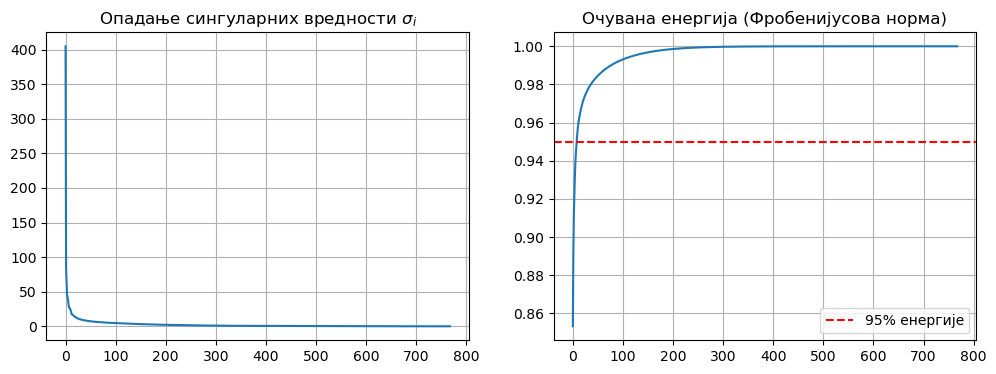

In [23]:
U, Sigma, Vt = spl.svd(A, full_matrices=False)

# Vizuelizacija opadanja singularnih vrednosti
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(Sigma)
plt.title("Опадање сингуларних вредности $\sigma_i$")
plt.grid(True)

plt.subplot(1, 2, 2)
energija = np.cumsum(Sigma**2) / np.sum(Sigma**2)
plt.plot(energija)
plt.axhline(y=0.95, color='r', linestyle='--', label='95% енергије')
plt.title("Очувана енергија (Фробенијусова норма)")
plt.legend()
plt.grid(True)

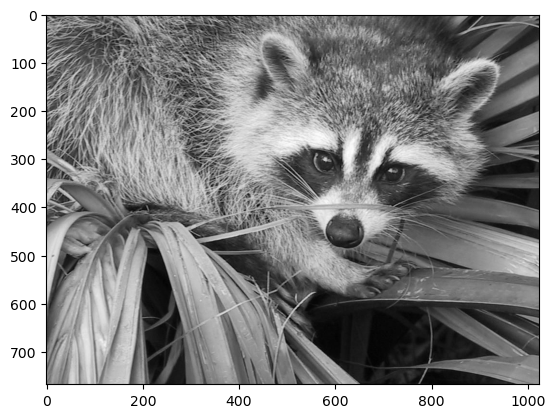

In [26]:
plt.imshow(rakun, cmap="gray");

In [27]:
U, Sigma, Vt=spl.svd(rakun)
U.shape, Sigma.shape, Vt.shape

((768, 768), (768,), (1024, 1024))

Примећујемо да сингуларне вредности редног броја између $100$ и $200$ (и надаље) постају занемарљиво мале у односу на првих неколико. Због тога матрицу ранга $768$ можемо да заменимо матрицом бар $3$ пута мањег ранга.

In [ ]:
# Funkcija za izračunavanje uštede memorije
def usteda_memorije(m, n, k):
    original = m * n
    kompresovano = k * (m + n + 1)
    return 100 * (1 - kompresovano / original)

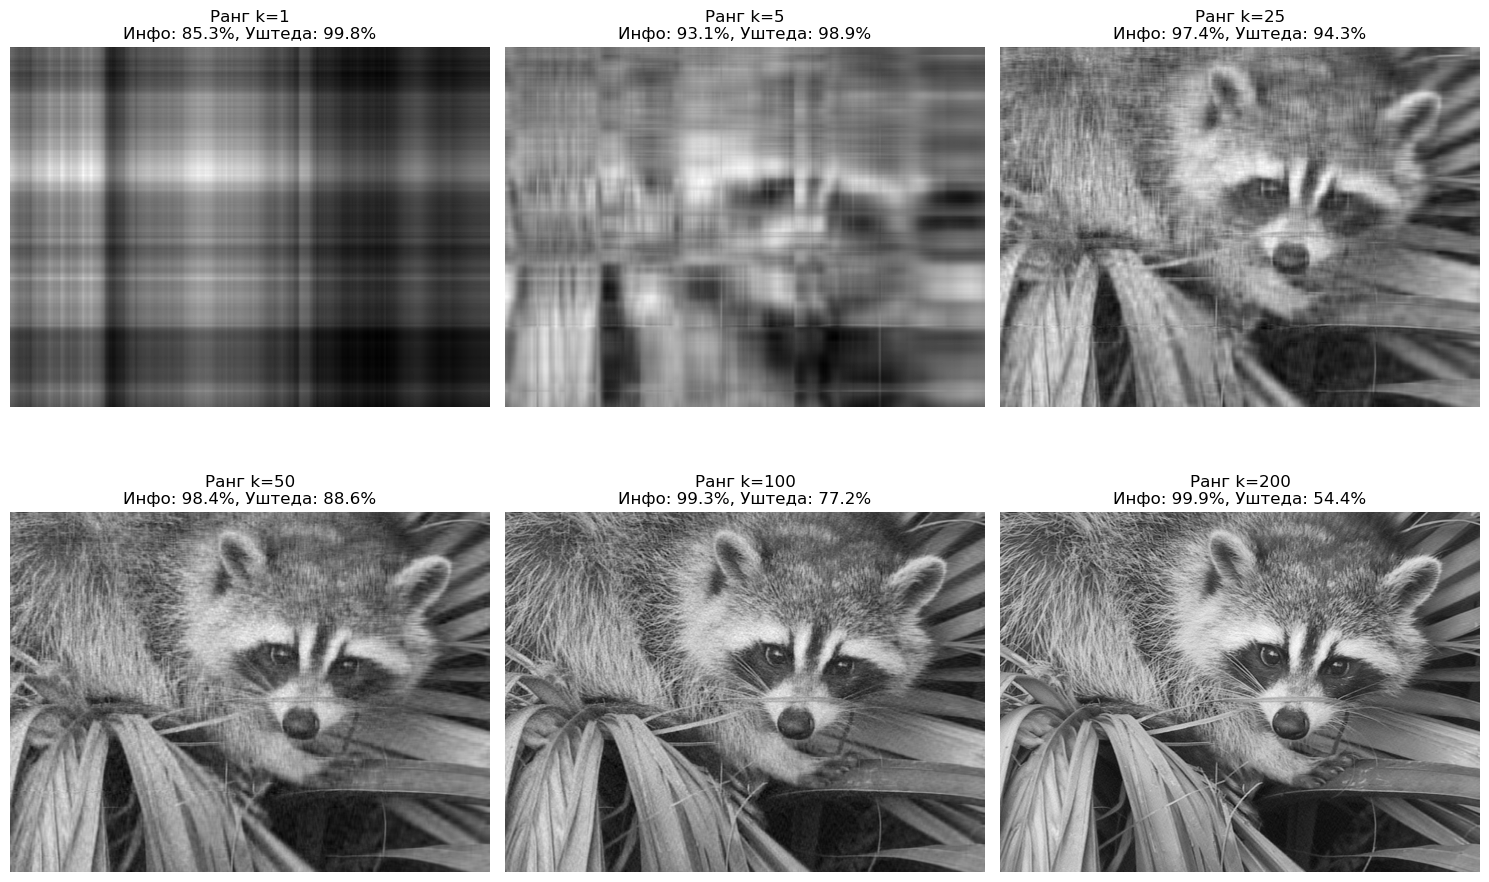

In [29]:
# Prikaz aproksimacija
rangovi = [1, 5, 25, 50, 100, 200]
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, k in enumerate(rangovi):
    # Rekonstrukcija Ak = U[:,:k] * Sigma[:k] @ Vt[:k,:]
    Ak = (U[:, :k] * Sigma[:k]) @ Vt[:k, :]
    
    proc_info = energija[k-1] * 100
    proc_mem = usteda_memorije(A.shape[0], A.shape[1], k)
    
    axes[i].imshow(Ak, cmap="gray")
    axes[i].set_title(f"Ранг k={k}\nИнфо: {proc_info:.1f}%, Уштеда: {proc_mem:.1f}%")
    axes[i].axis('off')

plt.tight_layout();

**Шта смо научили из овог примера?**

**Компресија.**
Са само $k = 50$ компоненти (што је мање од $7\%$ оригиналног ранга),
успели смо да сачувамо више од $90\%$ енергије слике.
Слика је већ тада потпуно препознатљива.

**Шум.}**
Мале сингуларне вредности $(\sigma_{k+1}, \ldots)$
често представљају ситне детаље или шум.
Њиховим одбацивањем вршимо својеврсну „глаткост” (smoothing) слике.

**Нумерички ранг.**
Иако је матрица можда формално пуног ранга,
њен \emph{нумерички ранг} за дати праг толеранције може бити знатно мањи.

***

## Анализа главних компоненти (PCA)


PCA ([Principal Component Analysis](https://en.wikipedia.org/wiki/Principal_component_analysis)) представља један од поступака редукције димензионалности податка. Користи се као корак у претпроцесирању података, тј. као припрема за неки од алгоритама машинског учења. Циљ је свести број карактеристика података (димензија) на кључне карактеристике. 

Претпоставимо да имамо велики обим високодимензионалних података. Рецимо да се ради о подацима о $10000$ људи и њиховим оценама $250$ филмова. Подаци су смештени у матрицу $A\in\mathcal{M}_{250\times10000}.$ Свака колона је вектор укуса једне од особа. Свака врста је вектор квалитета једног од филмова. Природно је питање да ли је потребно заиста $250$ димензија да би се описао укус једне особе, тј. да ли ови вектори леже у неком потпростору мање димензије? Могу ли се уочити комбинације филмова који праве преломну разлику између класа различитих укуса?

Слично претходном проблему, приликом процене цене некретнина користи се база података о сваком стану или кући са подацима као што су реон, година изградње, квадратура, број соба, итд. Неке од карактеристика су међусобно повезане па не морају појединачно да се користе у брзој процени цене некретнине. Како одлучити шта су кључне карактеристике?

Сваки од наведених примера преведен у језик линеарне алгебре може да се формулише на следећи начин:
> За дати скуп од $n$ података димензије $m$ и за природан број $k<m,n,$ како одредити  $k-$димензионални потпростор који најбоље описује дати скуп података? Под најбољим описом подразумевамо да је тај потпростор на најмањем растојању од скупа податка.

Да бисмо решили овај проблем потребно је да дефинишемо растојање скупа тачака од потпростора. То ће онда представљати и функцију циља коју желимо да минимизирамо.

Нека је дат скуп тачака преко њихових вектора положаја $A=\{a_1,a_2,\dots,a_n\}\subset\mathbb{R}^m.$ Блискост скупа $A$ и потпростора $V\subset\mathbb{R}^m$ изражавамо преко квадрата збира растојања појединачних тачака овог скупа од потпростора $V,$
$$d(A,V)^2=\sum_{i=1}^nd(a_i,V)^2.$$

Означимо са $P_V\in\mathcal{M}_{m\times m}$ матрицу пројекције на потпростор $V.$ Растојање $d(a_i,V)$ је тада дато са 
$$d(a_i,V)=\|a_i-P_Va_i\|.$$
С обзиром да се ради о ортогоналном растојању, на основу Питагорине теореме имамо да је
$$d(a_i,V)^2=\|a_i-P_Va_i\|^2=\|a_i\|^2-\|P_Va_i\|^2.$$
<div>
   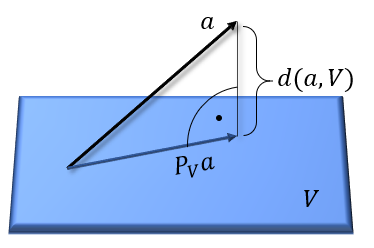  
</div>

Због тога је
$$d(A,V)^2=\sum_{i=1}^nd(a_i,V)^2=\sum_{i=1}^n\|a_i\|^2-\sum_{i=1}^n\|P_Va_i\|^2.$$
Уколико желимо да минимизирамо овај израз неопходно је постићи максимум суме $\displaystyle\sum_{i=1}^n\|P_Va_i\|^2.$

Означимо са $\widehat{V}$ потпростор димензије $k$ за који важи
$$\displaystyle\sum_{i=1}^n\|P_{\widehat{V}}a_i\|^2=\max_{{\rm dim}(V)= k}\displaystyle\sum_{i=1}^n\|P_Va_i\|^2.$$
За познавање потпростора $\widehat{V}$ довољно је познавање једне његове базе. Показаћемо како SVD обезбеђује ову базу.

Нека су координате тачака $a_1,a_2,\dots,a_n$ смештене у колоне матрице $A\in\mathcal{M}_{m\times n},$
$$A=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&\phantom{W}&\phantom{W}\\
a_1&a_2&\dots&a_n\\
\phantom{W}&\phantom{W}&\phantom{W}&\phantom{W}
\end{array}\right].$$
Користимо редуковану SVD матрице $A,$ ${\rm rang}(A)=r=\min\{m,n\},$
$$A=U_r\Sigma_{r\times r}V_r^T,\qquad 
U_r=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&\phantom{W}&\phantom{W}\\
u_1&u_2&\dots&u_r\\
\phantom{W}&\phantom{W}&\phantom{W}&\phantom{W}
\end{array}\right],\qquad 
V_r=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&\phantom{W}&\phantom{W}\\
v_1&v_2&\dots&v_r\\
\phantom{W}&\phantom{W}&\phantom{W}&\phantom{W}
\end{array}\right],$$
где сингуларни вектори $u_1,u_2,\dots,u_r\in\mathbb{R}^m$ одговарају редом сингуларним вредностима $\sigma_1\geq\sigma_2\geq\dots\geq\sigma_r>0,$
$$Av_i=\sigma_i u_i\quad\Longleftrightarrow\quad u_i^TA=\sigma_iv_i^T,\quad i=1,2,\dots,r.$$

На основу последице 3. радне свеске 22SVD знамо да се најдуже пројекције вектора колона дешавају управо дуж вектора ортонормиране базе простора $\mathcal{R}(A),$ коју чине сингуларни вектори $u_1,u_2,\dots,u_r.$ Због тога је тражени потпростор димензије $k<r$ задат са првих $k$ вектора ове базе,
$$\widehat{V}=\mathcal{L}(u_1,u_2,\dots,u_k).$$

Означимо $A_k=U_k\Sigma_{k\times k}V_k^T$ редуковану SVD матрице $A_k.$ Њене колоне су пројекције колона $a_i$ на потпростор $\widehat{V}=\mathcal{R}(U_k).$ 
\begin{align}
U_kU_k^TA&=U_kU_k^TU_r\Sigma_{r\times r}V_r^T=U_kU_k^T
\begin{bmatrix}U_k&U_{r-k}\end{bmatrix}
\begin{bmatrix}\Sigma_{k\times k}&O_{k\times(r-k)}\\O_{(r-k)\times k}&\Sigma_{(r-k)\times(r-k)}\end{bmatrix}
\begin{bmatrix}V_k^T\\V_{r-k}^T\end{bmatrix}\\
&=U_k\begin{bmatrix}U_k^TU_k&U_k^TU_{r-k}\end{bmatrix}
\begin{bmatrix}\Sigma_{k\times k}&O_{k\times(r-k)}\\O_{(r-k)\times k}&\Sigma_{(r-k)\times(r-k)}\end{bmatrix}
\begin{bmatrix}V_k^T\\V_{r-k}^T\end{bmatrix}\\
&=U_k\begin{bmatrix}I_k&O_{k\times(r-k)}\end{bmatrix}
\begin{bmatrix}\Sigma_{k\times k}&O_{k\times(r-k)}\\O_{(r-k)\times k}&\Sigma_{(r-k)\times(r-k)}\end{bmatrix}
\begin{bmatrix}V_k^T\\V_{r-k}^T\end{bmatrix}\\
&=U_k\begin{bmatrix}\Sigma_{k\times k}&O_{k\times(r-k)}\end{bmatrix}
\begin{bmatrix}V_k^T\\V_{r-k}^T\end{bmatrix}=U_k\Sigma_{k\times k}V_k^T=A_k.
\end{align}

Координате вектора-колона матрице $A_k$ у односу на базу састављену од вектора $u_1,u_2,\dots,u_k$ садржане су у колонама матрице $Z=\Sigma_{k\times k}V_k^T=U_k^TA_k=U_k^TA\in\mathcal{M}_{k\times n}.$ На тај начин, уколико је потребно, уместо да баратамо пуном матрицом $A\in\mathcal{M}_{m\times n}$ можемо да радимо само координатама пројекција њених колона, што је матрица значајно мање димензије.

Приметимо да у било ком тренутку на основу матрице $Z$ можемо да реконструишемо оригиналну матрицу $A,$ додуше уз одређени губитак вредности. У радној свесци 22SVD у оквиру задатка 3 показано је да је $U_k^+=U_k^T\quad\Longrightarrow\quad (U_k^T)^+=U_k.$ Због тога је 
$$A\approx A_k=U_kZ.$$

Уколико се све колоне матрице $A$ замене својим пројекцијама на потпростор $\widehat{V},$ тј. ако се матрица $A$ замени матрицом $A_k,$ грешка апроксимације износи 
$$\|A\|_F^2-\|A_k\|_F^2=\sigma_{k+1}^2+\dots+\sigma_r^2.$$

Један од кључних елемената приликом анализе главних компоненти јесте центрирање податка. Да би подаци лежали у векторском потпростору што мање димензије неопходно је да буду центрирани. Разлог лежи у томе да сваки векторски простор мора да садржи нула-вектор $\theta.$ Центрирањем података вршимо њихову транслацију где се подаци групишу око координатног почетка.

**Пример 5.** Креираћемо линеарно корелисане податке њиховим $x$ и $y$ координатама. Скуп података биће дводимезионалне тачке $A=\{a_1,a_2,\dots,a_n\}\subset\mathbb{R}^2.$ Колоне матрице $A\in\mathcal{M}_{2\times n}$ садржаће координате тачака блиске правој.
За оригиналне и центриране податке одредићемо праве које су решења одговарајућих проблема најмањих квадрата. Центрирање вршимо дуж сваке врсте матрице $A,$ тј. центрирамо  $x$ координате тачака и центрирамо њихове $y$ координате.

In [30]:
n=20
x = 2*rndm.rand(n)-1
y = 2+3*x+rndm.randn(n)
p1=np.polyfit(x,y, 1,rcond=None, full=True)
A=np.stack((x,y),axis=0)
A

array([[-0.6745903 , -0.92124122,  0.45076145, -0.77197573, -0.88622532,
        -0.88025746, -0.92405557, -0.85685941,  0.00647917,  0.03721641,
        -0.33072653, -0.75351628, -0.04463131,  0.6046594 , -0.58411039,
        -0.76447557, -0.62865984,  0.51293828,  0.39220399,  0.50471371],
       [ 0.69369962, -2.85856126,  0.86964833,  1.69761636, -0.00839684,
        -1.35471239, -0.88331226,  0.87316042,  2.54517723,  2.31563321,
         0.81918986,  0.09748716,  1.4191187 ,  5.00028713, -0.13038997,
         1.22835087,  0.72020019,  4.15596737,  3.99370965,  3.34319853]])

In [31]:
mu=A.mean(axis=1)
Ac=(A.T-mu).T
p2=np.polyfit(Ac[0],Ac[1], 1,rcond=None, full=True)

In [32]:
p1 , p2

((array([2.80301987, 2.13956627]),
  array([23.07379627]),
  2,
  array([1.22709579, 0.70301915]),
  4.440892098500626e-15),
 (array([ 2.80301987e+00, -3.26445912e-16]),
  array([23.07379627]),
  2,
  array([1., 1.]),
  4.440892098500626e-15))

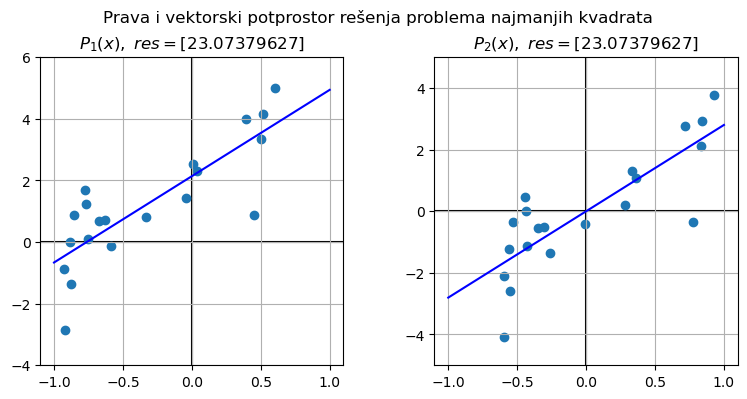

In [33]:
t=np.linspace(-1,1)
slika, ax = plt.subplots(1, 2,figsize=(9,4)) 
slika.suptitle('Prava i vektorski potprostor rešenja problema najmanjih kvadrata',y=1)
slika.subplots_adjust(wspace = 0.3, hspace=0.5)

pom=np.polyval(p1[0],t)
plt.subplot(1, 2, 1)
plt.title(r"$P_1(x),\ res=$"+str(p1[1]))
plt.plot(t,pom,'-b')
plt.scatter(x,y)
plt.ylim([-4, 6])
plt.axhline(color='black', zorder=-1)
plt.axvline(color='black', zorder=-1)
plt.grid();

pom=np.polyval(p2[0],t)
plt.subplot(1, 2, 2)
plt.title(r"$P_2(x),\ res=$"+str(p2[1]))
plt.plot(t,pom,'-b')
plt.scatter(Ac[0],Ac[1])
plt.ylim([-5, 5])
plt.axhline(color='black', zorder=-1)
plt.axvline(color='black', zorder=-1)
plt.grid();

Примећујемо да за центриране податке права линеарне регресије пролази кроз координатни почетак, слика десно. Та права представља векторски потпростор најближи у смислу најмањих квадрата. У случају нецентрираних података, слика лево, права линеарне регресије представља афини потпростор, не и векторски потпростор. Када бисмо тражили најближи векторски потпростор оваквим нецентрираним подацима ниједна права кроз координатни почетак не би била довољно добра апроксимација.

***

**Пример 6.** Приказаћемо транслацију података њиховим центрирањем и у $3D.$

In [34]:
n3=25
x3 = rndm.uniform(-1,3,n3)
xc=x3-x3.mean()
y3 = rndm.uniform(2,4,n3)
yc=y3-y3.mean()
z3=2*y3-x3+0.3*rndm.randn(n3)
zc=z3-z3.mean()

In [35]:
X,Y=np.meshgrid([-1,3],[2,4])
Z=2*Y-X

In [36]:
XC,YC=np.meshgrid([-2,2],[-2,2])
ZC=2*YC-XC

In [37]:
%matplotlib notebook

<IPython.core.display.Javascript object>


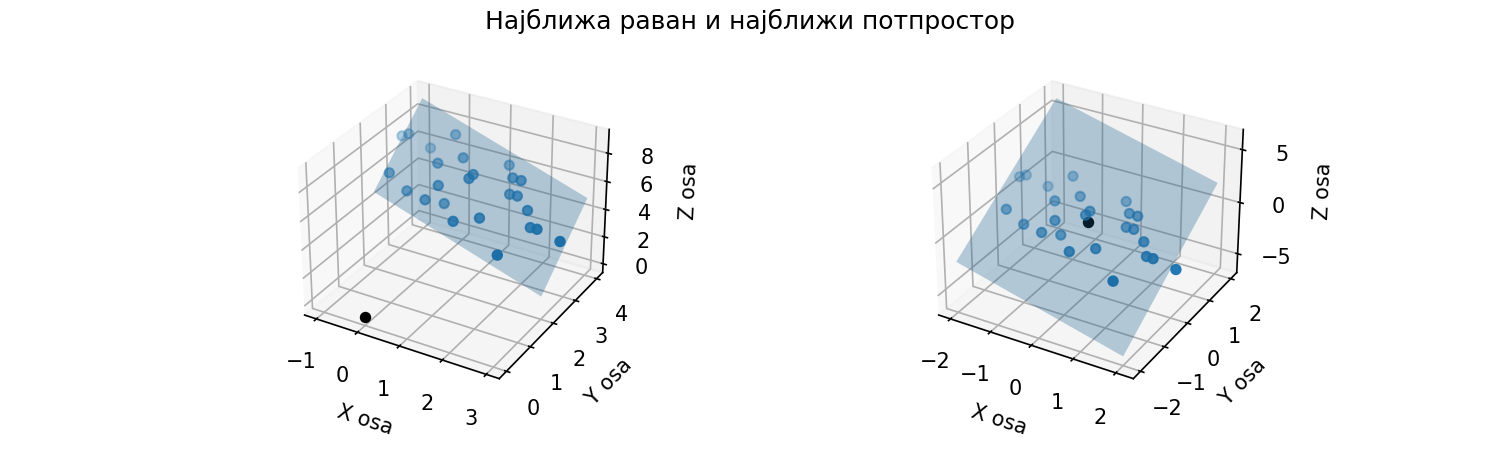

In [38]:
slika= plt.figure(figsize=(10,3)) 
slika.suptitle('Најближа раван и најближи потпростор')
slika.subplots_adjust(hspace=0.5)

ax1 = slika.add_subplot(121, projection='3d')
ax1.set(xlabel='X osa', ylabel='Y osa', zlabel='Z osa')
ax1.scatter(x3,y3,z3)
ax1.scatter([0],[0],[0],marker='o', color='k')
ax1.plot_surface(X,Y,Z,alpha=0.3);

ax2 = slika.add_subplot(122, projection='3d')
ax2.set(xlabel='X osa', ylabel='Y osa', zlabel='Z osa')
ax2.scatter(xc,yc,zc)
ax2.plot_surface(XC,YC,ZC,alpha=0.3)
ax2.scatter([0],[0],[0],marker='o', color='k');

In [39]:
%matplotlib inline

***

Преведимо сада геометријску формулацију претходне анализе на проблеме података. Претпоставимо да је матрица $A\in\mathcal{M}_{m\times n}$ са подацима размештеним тако да је $m$ карактеристика или обележја (feature) мерено $n$ пута (samples).

|подаци   |$1.$ мерење|$2.$ мерење|$\dots$|$n.$ мерење|
|---|---|---|---|---|
|$1.$ обележје|   |   |   |   |
|$2.$ обележје|   |   |   |   |
|$\vdots$ |   |   |   |   |
|$m.$ обележје|   |   |   |   |

Једна врста матрице $A$ носи резултате мерења једне карактеристике.  У примерима 5 и 6 прва врста матрице садржала је $x$ координате различитих тачака, друга врста носила је $y$ координате тачака, итд. Дакле, координате су везане за различита обележја податка. Дуж једне координатне осе прате се вредности једног обележја. Због тога центрирање вредности дуж једне координате има и статистичког смисла. Претпоставка је да се узорковане вредности једног обележја понашају на сличан начин.

Тачка $m-$димензионалног простора носи податке једног мерења $m$ карактеристика. Због тога колоне матрице $A$ зовемо узорцима или подацима, а врсте матрице $A$ зовемо вектори-обележја.
$$A=\left[\begin{array}{c|c|c|c}
у&у&\phantom{W}&у\\
з&з&\phantom{W}&з\\
о&о&\phantom{W}&о\\
р&р&\dots&р\\
а&а&\phantom{W}&а\\
к&к&\phantom{W}&к\\
1&2&\phantom{W}&m
\end{array}\right]=\left[\begin{array}{c}
\mbox{вектор обележја 1}^T\\\hline
\mbox{вектор обележја 2}^T\\\hline
\vdots\\\hline
\mbox{вектор обележја }m^T
\end{array}\right].$$
Претходни проблем проналажења најближег потпростора односи се на векторе узорака, тј. колоне матрице $A,$
$$A=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&\phantom{W}&\phantom{W}\\
a_1&a_2&\dots&a_n\\
\phantom{W}&\phantom{W}&\phantom{W}&\phantom{W}
\end{array}\right]=\left[\begin{array}{c}
\phantom{WW}o_1^T\phantom{WW}\\\hline
\phantom{WW}o_2^T\phantom{WW}\\\hline
\vdots\\\hline
\phantom{WW}o_m^T\phantom{WW}
\end{array}\right].$$

Центрирамо векторе обележја, тј. векторе-врста матрице $A$ одузимањем средње вредности од сваке врсте. То је садржај матрице $A_C.$ 
\begin{align}
\mu_i&=\dfrac{o_i^T\mathbb{1}}{\mathbb{1}^T\mathbb{1}},\qquad \mathbb{1}=\begin{bmatrix}1&1&\dots&1\end{bmatrix}^T\in\mathbb{R}^n,\\
A_C&=\left[\begin{array}{c}
\phantom{WW}o_1^T-\mu_1\mathbb{1}^T\phantom{WW}\\\hline
\phantom{WW}o_2^T-\mu_2\mathbb{1}^T\phantom{WW}\\\hline
\vdots\\\hline
\phantom{WW}o_m^T-\mu_m\mathbb{1}^T\phantom{WW}
\end{array}\right]=A\left(I-\dfrac{\mathbb{1}\mathbb{1}^T}{\mathbb{1}^T\mathbb{1}}\right)\\
&=\left[\begin{array}{c}
\phantom{WW}c_1^T\phantom{WW}\\\hline
\phantom{WW}c_2^T\phantom{WW}\\\hline
\vdots\\\hline
\phantom{WW}c_m^T\phantom{WW}
\end{array}\right].
\end{align}
Због центрирања, сума колона матрице $A_C$ је нула-вектор (сума елемената дуж сваке врсте је $0$). 
$$A_C\mathbb{1}=A\left(I-\dfrac{\mathbb{1}\mathbb{1}^T}{\mathbb{1}^T\mathbb{1}}\right)\mathbb{1}
=A\left(\mathbb{1}-\dfrac{\mathbb{1}\mathbb{1}^T\mathbb{1}}{\mathbb{1}^T\mathbb{1}}\right)
=A\left(\mathbb{1}-\dfrac{\mathbb{1}^T\mathbb{1}}{\mathbb{1}^T\mathbb{1}}\mathbb{1}\right)
=A(\mathbb{1}-\mathbb{1})=\theta.$$

На овај начин долазимо до објашњења поступка PCA кроз статистичке термине. Матрица $A_C$ носи информације о одступању компоненти вектора-обележја од њихове средње вредности. Због тога је тотална варијанса скупа података дата изразом
$$T=\dfrac{\|A_C\|_F^2}{m}=\dfrac{\|c_1\|^2+\|c_2\|^2+\dots+\|c_m\|^2}{m}.$$
Ово је траг Грамове матрице $S=\dfrac{A_CA_C^T}{m}.$ Симетрична матрица $S$ садржи истовремено информације о варијанси и коваријанси вектора обележја. Дијагонални елементи матрице $S$ су варијансе вектора-врста матрице $A,$ а ван дијагонални елементи садрже њихове коваријансе. Матрица $S$ садржи податке о нивоу линеарне корелисаности између посматраних карактеристика.

Уколико сопствене вредности матрице коваријансе $S$ поређамо у опадајући низ, одговарајући ортонормирани сопствени вектори (главне компоненте) указују на неке нове карактеристике података које носе највише варијабилности, а међусобно су некорелисане. На тај начин траг матрице $S$ повезује тоталну варијансу са сумом варијанси главних компоненти. Одговарајуће податке читамо директно из SVD матрице $A_C,$ с обзиром да важи
$$A_C=U_r\Sigma_{r\times r} V_r^T\quad\Longrightarrow\quad A_CA_C^T=U_r\Sigma_{r\times r}^2U_r^T,$$
$$U_r=\left[\begin{array}{c|c|c|c}
\phantom{w}&\phantom{w}&\phantom{w}&\phantom{w}\\
u_1&u_2&\dots&u_r\\
\phantom{w}&\phantom{w}&\phantom{w}&\phantom{w}
\end{array}\right],\qquad \Sigma_{r\times r}={\rm diag}(\sigma_1,\sigma_2,\dots,\sigma_r).$$
Одатле је тотална варијанса
$$T=\dfrac{\|A_C\|_F^2}{m}={\rm tr}(S)=\dfrac{\sigma_1^2+\sigma_2^2+\dots+\sigma_r^2}{m}.$$

Прва главна компонента $u_1$ заслужна је за $\dfrac{\sigma_1^2}{mT}$ тоталне варијансе. Наредни сингуларни вектор $u_2$ доприноси са $\dfrac{\sigma_2^2}{mT}$ удела у тоталној варијанси. Сваки наредни сингуларни вектор служи да на најбољи начин опише преосталу варијабилност у подацима, а сви заједно описују тоталну варијансу.

Поента Eckart-Young-Mirsky теореме јесте да првих $k$ сингуларних вектора описују садржај матрице података више него било којих других $k$ ортонормираних вектора. Сингуларни вектори $u_1,u_2,\dots,u_k$ су резултат линеарних комбинација полазних обележја, због тога представљају мањи скуп изведених обележја која ефикасније описују полазни скуп података. 

**Пример 7.** Израчунаћемо матрицу коваријансе за податке из примера 6.

In [40]:
S=Ac@Ac.T/2
S

array([[ 3.08468689,  8.64643866],
       [ 8.64643866, 35.77303754]])

Правац простирања једнодимензионалног потпростора најближег подацима одређује сопствени вектор који одговара доминантној сопственој вредности.

In [41]:
sop_vr, Q=np.linalg.eigh(S)
sop_vr

array([ 0.93851423, 37.9192102 ])

In [42]:
Q[:,1]

array([0.24090443, 0.97054884])

In [43]:
Q[1,1]/Q[0,1]

4.028771226416794

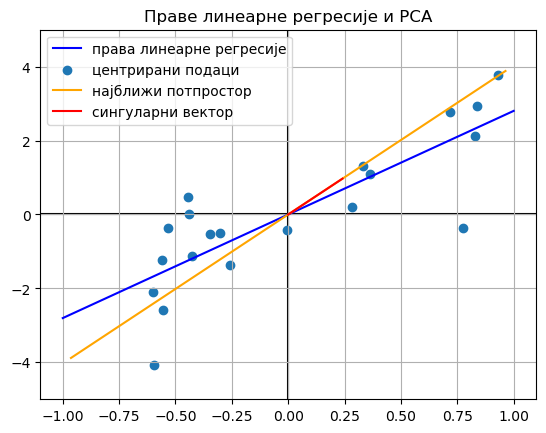

In [44]:
plt.title("Праве линеарне регресије и PCA")
plt.plot(t,pom,'-b',label="права линеарне регресије")
plt.scatter(Ac[0],Ac[1],label="центрирани подаци")
koef=np.array([-4,4])
plt.plot(koef*Q[0,1],koef*Q[1,1],'-',color="orange",label="најближи потпростор")
plt.plot([0,Q[0,1]],[0,Q[1,1]],'-r',label="сингуларни вектор")
plt.ylim([-5, 5])
plt.axhline(color='black', zorder=-1)
plt.axvline(color='black', zorder=-1)
plt.grid()
plt.legend();

Приметимо да се правац простирања најближе праве у смислу PCA и проблема најмањих квадрата разликује. Разлог лежи у начину мерења растојања тачака од праве. У проблему најмањих квадрата мере се растојања само по $y$ компоненти, док у анализи главним осама се мере ортогонална растојања тачака од праве. Због тога се анализа главних компоненти још назива и ортогонална регресија или ортогонални најмањи квадрати.
<div>
   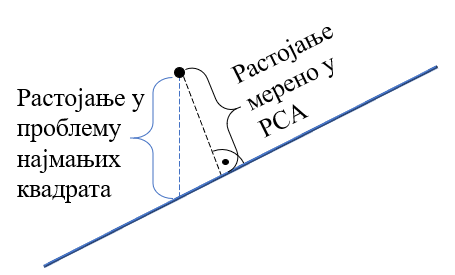  
</div>

***

**Пример 8.** Искористићемо познату базу MNIST слика ручно писаних цифара. Слике су црно-беле формата $28\times28$ пиксела па представљају векторе димензије $28\cdot28=784.$ Различита обележја су вредности пиксела на одговарајућој позицији. 

In [45]:
m=28*28
m

784

Наредне 4 кодне ћелије активирати према потреби.

In [46]:
import tensorflow as tf
import tensorflow_datasets as tfds

In [47]:
baza = tfds.load('mnist', split='train', as_supervised=True)
n=len(baza)
n

60000

Учитана база састоји се од $60000$ сличица са пратећим подацима. Приказаћемо првих $10$ података учитане базе.

In [48]:
ds10 = baza.take(10)
len(ds10)

10

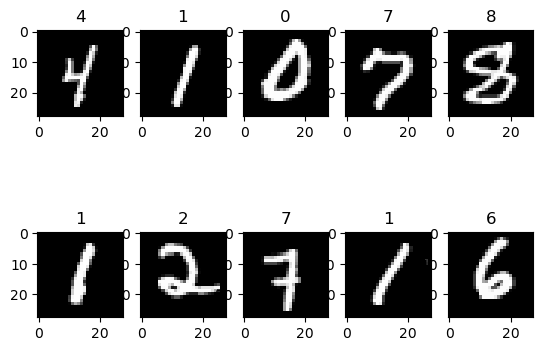

In [49]:
podaci=tfds.as_numpy(ds10)
k=1
for slika, labela in podaci:
    plt.subplot(2, 5, k)
    plt.imshow(slika, cmap="gray")
    plt.title(labela)
    k+=1

Креирајмо сада матрицу слика $A,$ са опсегом вредности на $[0,1],$ а затим центрирамо колоне.

In [50]:
A=np.empty((m,n))
labela=np.empty(n)
j=0
for slika, l in tfds.as_numpy(baza):
    A[:,j]=slika.reshape(m,)
    labela[j]=l
    j+=1   

In [51]:
np.min(A), np.max(A)

(0.0, 255.0)

In [52]:
A/=255  #dovodjenje na vrednosti [0,1]
mu=A.mean(axis=1)
Ac=A-mu.reshape(m,1) 

Резултат центрирања погледаћемо на примеру првих $10$ слика.

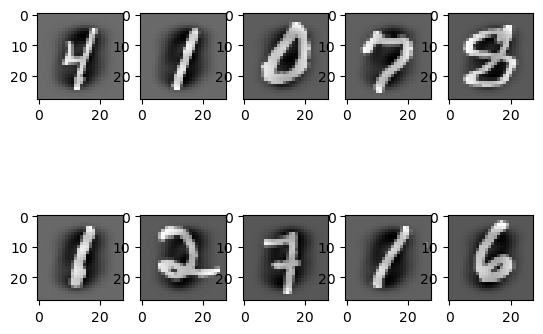

In [53]:
for k in range(10):
    plt.subplot(2, 5, k+1)
    plt.imshow(Ac[:,k].reshape(28,28), cmap="gray")

In [54]:
U, Sigma, VT=spl.svd(Ac,full_matrices=False)
U.shape

(784, 784)

Одредићемо тоталну варијансу података као норму вектора сингуларних вредности као и кумулативни проценат удела сингуларних вектора у тоталној варијанси.

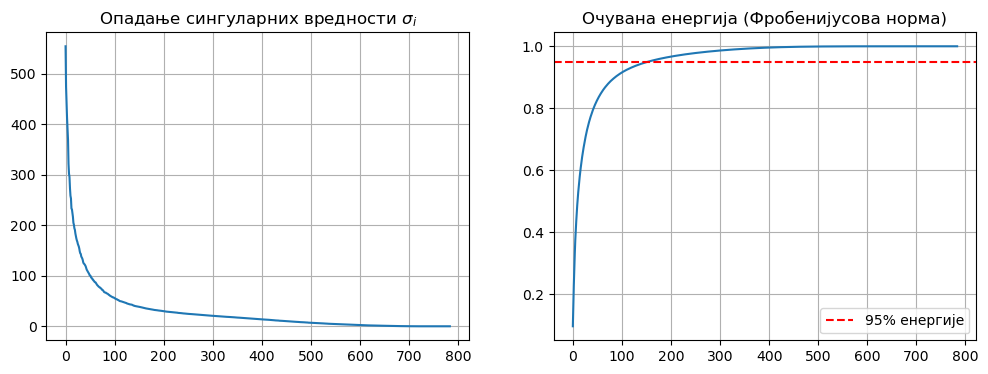

In [56]:
# Vizuelizacija opadanja singularnih vrednosti
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(Sigma)
plt.title("Опадање сингуларних вредности $\sigma_i$")
plt.grid(True)

plt.subplot(1, 2, 2)
energija = np.cumsum(Sigma**2) / np.sum(Sigma**2)
plt.plot(energija)
plt.axhline(y=0.95, color='r', linestyle='--', label='95% енергије')
plt.title("Очувана енергија (Фробенијусова норма)")
plt.legend()
plt.grid(True)

Закључујемо да приближно првих $150$ сингуларних вектора описује $95\%$ тоталне варијансе, а првих $250$ описује $98\%$ тоталне варијансе. Због тога, довољно је да радимо са матрицом података $150\times 60000$ или $250\times 60000$ уместо полазне.

Смањење димензионалности проверићемо визуелно на првих $10$ података базе.

In [58]:
k=150
Uk, Sigmak, Vkt=U[:,:k], Sigma[:k], VT[:k]
A10=(Uk*Sigmak)@Vkt[:,:10]
A10t=(A10.T+mu).T

In [60]:
proc_info = energija[k-1] * 100
proc_mem = usteda_memorije(A.shape[0], A.shape[1], k)
proc_info, proc_mem 

(94.83564188145832, 80.61702806122449)

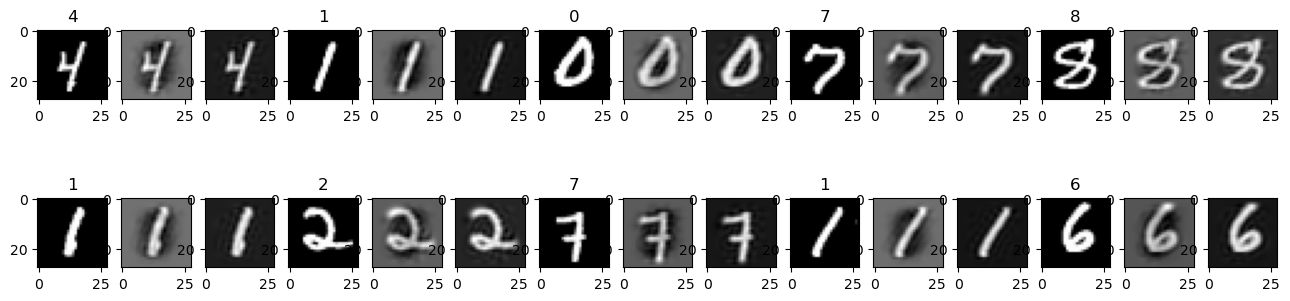

In [61]:
k=0
slika=plt.figure(figsize=(16,4))
for slika, l in podaci:
    plt.subplot(2, 15, 3*k+1)
    plt.imshow(slika, cmap="gray")
    plt.title(l)
    plt.subplot(2, 15, 3*k+2)
    plt.imshow(A10[:,k].reshape(28,28), cmap="gray")
    plt.subplot(2, 15, 3*k+3)
    plt.imshow(A10t[:,k].reshape(28,28), cmap="gray")
    k+=1

In [62]:
k=250
Uk, Sigmak, Vkt=U[:,:k], Sigma[:k], VT[:k]
A10=(Uk*Sigmak)@Vkt[:,:10]
A10t=(A10.T+mu).T
proc_info = energija[k-1] * 100
proc_mem = usteda_memorije(A.shape[0], A.shape[1], k)
proc_info, proc_mem 

(97.81070442612376, 67.69504676870748)

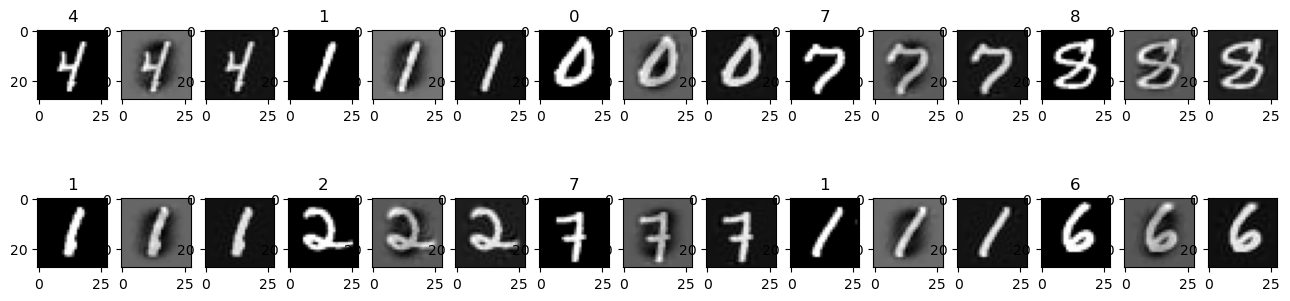

In [63]:
k=0
slika=plt.figure(figsize=(16,4))
for slika, l in podaci:
    plt.subplot(2, 15, 3*k+1)
    plt.imshow(slika, cmap="gray")
    plt.title(l)
    plt.subplot(2, 15, 3*k+2)
    plt.imshow(A10[:,k].reshape(28,28), cmap="gray")
    plt.subplot(2, 15, 3*k+3)
    plt.imshow(A10t[:,k].reshape(28,28), cmap="gray")
    k+=1

***

**Пример 9.** Класификација методом потпростора (Subspace Method)

Класификација података је поступак сличан кластеризацији. Разлика се огледа у постојању унапред познатих класа. Задатак поступка јесте одређивање припадности новог податка некој од постојећих класа. Наведени поступак спада у методе [надгледаног учења](https://en.wikipedia.org/wiki/Supervised_learning). 
У овом примеру бавићемо се методом потпростора (subspace method). Идеја је да се свака од класа представи неким потпросторм у великодимензионалном векторском простору. То би спадало у део алгоритма који називамо тренинг. У сврхе представљања класа користимо SVD (PCA) познатих елемената за сваку класу понаособ. У сврхе показног примера искористићемо поново базу MNIST слика ручно писаних цифара.

Сваку класу (цифре од 0 до 9) моделујемо као посебан потпростор ниске димензије користећи PCA над тренинг подацима те класе. Нови (тест) податак класификујемо у ону класу чији му је потпростор "најближи".

Искористићемо учитане податке из претходног примера, матрицу A и вектор labela. Издвајамо најпре тренинг скуп по принципу случајног избора. На пример 80% података користимо за тренинг.

In [64]:
permutacija=rndm.permutation(n)
split_point = int(0.8 * n)
train_idx = permutacija[:split_point]
test_idx = permutacija[split_point:]

A_train = A[:, train_idx]
l_train = labela[train_idx]
A_test = A[:, test_idx]
l_test = labela[test_idx]

Вршимо центрирање тренинг података унутар сваке класе понаособ и одређивање ортонормиране базе најближег потпростора. За димензију потпростора узимамо број сингуларних вредности које описују $95\%$ тоталне варијансе.

In [66]:
mu_klasa=np.empty((m,10))
for i in range(10):
    idx=l_train==i
    mu_klasa[:,i]=A_train[:,idx].mean(axis=1)
    A_train[:,idx]-=mu_klasa[:,i].reshape(m,1)

#конструкција потпростора за сваку цифру врши се избором базе
prag=0.95
baze=[]
for i in range(10):
    idx=l_train==i
    U,Sigma,_=spl.svd(A_train[:,idx],full_matrices=False)
    S=Sigma**2
    T=np.sum(S)
    procenat=np.cumsum(S)/T
    r=np.sum(procenat<=prag)
    baze.append(U[:,:r])

За тест податке рачунамо ортогонална растојања од одговарајућих класа (потпростора). То значи претходну транслацију сваког тест податка за одговарајући средњи вектор класе.

In [67]:
rastojanja=np.empty((10,test_idx.size))
for i in range(10):
    pom=A_test-mu_klasa[:,i].reshape(m,1)
    U=baze[i]
    pom-=U@(U.T@pom)
    rastojanja[i]=np.linalg.norm(pom , axis=0)

Класу тест података одређујемо на основу најкраћег растојања од потпростора.

In [68]:
test_klase=np.argmin(rastojanja, axis=0)
np.sum(test_klase==l_test), test_idx.size

(10748, 12000)

In [69]:
np.sum(test_klase==l_test)/ test_idx.size

0.8956666666666667

Примећујемо да поступак класификације има око 89% тачност. 
Интересантно је пробати претходни код за различите вредности prag. Може се уочити да са повећањем ове опције не долази до побољшања резултата класификације. Шта више, модел показује слабије перформансе док за prag=0.9 добијамо боље резултате. Разлог лежи у томе да за веће вредности prag долази до претрениравања модела (overfitting) са повећањем димензија потпростора којима су моделоване класе. Са друге стране, уколико је prag исувише мали имамо недовољно трениран модел (underfitting). 

То нарочито долази до изражаја када упоредимо резултате класификације на тренинг подацима.

In [70]:
rastojanja=np.empty((10,train_idx.size))
for i in range(10):
    pom=A_train-mu_klasa[:,i].reshape(m,1)
    U=baze[i]
    pom-=U@(U.T@pom)
    rastojanja[i]=np.linalg.norm(pom , axis=0)

In [71]:
trening_klase=np.argmin(rastojanja, axis=0)
np.sum(trening_klase==l_train), train_idx.size

(44374, 48000)

In [72]:
np.sum(trening_klase==l_train)/ train_idx.size

0.9244583333333334

За додатно објашњење обављене класификације искористићемо приказ матрицом конфузије. То је матрица чији елемент на позицији $(i,j)$ описује колико је елемената $i-$те класе класификовано у $j-$тој. На главној дијагонали на позицији $(i,i)$ је број добро класификованих елемената $i-$те класе.

In [73]:
from sklearn.metrics import confusion_matrix

In [74]:
M=confusion_matrix(l_test,test_klase)
print(M)

[[1050    1   35   15    0    4    2    0   47    0]
 [   0 1114   29    3   19    0    3    4  158    0]
 [   0    0 1148   15    9    0    0    2   34    0]
 [   5    0   47 1106    3    6    0    7   85    6]
 [   1    0   16    0 1100    1    1    6   22   16]
 [   3    0   14   78    1  827    5    1  100    3]
 [   5    0   12    4    3   21 1104    0   38    0]
 [   1    0   14   14   38    0    0 1105   21   26]
 [   1    2   16   31   12    5    1    2 1138    2]
 [   2    0    5    6   59    3    0   58   43 1056]]


In [75]:
procenti=np.diag(M)/np.sum(M,axis=1)
print(procenti) #procenti dobre klasifikacije po svakoj cifri

[0.90987868 0.83759398 0.95033113 0.8743083  0.94582975 0.80135659
 0.93007582 0.90648072 0.94049587 0.85714286]


In [76]:
print("Najgore klasifikovana cifra:",np.argmin(procenti)) 
print("Najbolje klasifikovana cifra:",np.argmax(procenti))

Najgore klasifikovana cifra: 5
Najbolje klasifikovana cifra: 2


Најгоре класификована цифра 5 је најчешће мешана са 3 и 8. То можемо да објаснимо и преко каноничких углова блиских нули између парова потпростора (пример 4, свеска 28SVD). Креираћемо матрицу која на главној дијагонали бележи димензију потпростора одговарајуће класе, а елемент на позицији $(i,j)$ описује број каноничких углова између потпростора $i-$те и $j-$те класе са вредношћу косинуса изнад $0.995.$ Ради се, наравно, о симетричној матрици.

In [77]:
np.arccos(0.995)

0.10004171361154007

In [78]:
dimenzije=np.empty((10,10))
for i in range(10):
    dimenzije[i,i]=baze[i].shape[1]
    for j in range(i+1,10):
        pom=baze[i].T@baze[j]
        mc,nc=pom.shape
        _,Sigma,_=spl.svd(pom,full_matrices=False)
        r=np.sum(Sigma>=0.995)
        dimenzije[i,j]=r
        dimenzije[j,i]=r

print(dimenzije)

[[114.  10.  34.  36.  25.  34.  28.  19.  34.  21.]
 [ 10.  70.  15.  14.  13.  12.   7.   7.  19.   7.]
 [ 34.  15. 141.  47.  34.  38.  29.  26.  41.  26.]
 [ 36.  14.  47. 136.  34.  48.  26.  28.  47.  27.]
 [ 25.  13.  34.  34. 134.  33.  22.  30.  37.  32.]
 [ 34.  12.  38.  48.  33. 129.  27.  24.  46.  26.]
 [ 28.   7.  29.  26.  22.  27. 111.  12.  27.  16.]
 [ 19.   7.  26.  28.  30.  24.  12. 119.  28.  34.]
 [ 34.  19.  41.  47.  37.  46.  27.  28. 135.  31.]
 [ 21.   7.  26.  27.  32.  26.  16.  34.  31. 110.]]


Из матрице видимо велику "линеарну зависност" између потпростора у контексту велике димензије потенцијалног пресека парова потпростора.

У оквиру истог примера приказаћемо још један приступ у класификацији. Као меру за класификацију уместо Еуклидове метрике можемо да користимо и угао између вектора тест примера и њихових пројекција на просторе класа.
$$\cos\angle(v,Pv)=\dfrac{v\cdot Pv}{\|v\|\,\|Pv\|}\stackrel{пр.3.,св. 26}{=}\dfrac{\|Pv\|^2}{\|v\|\,\|Pv\|}
=\dfrac{\|Pv\|}{\|v\|}\,.
$$

Уместо високодимензионалних потпростора којима су описане класе на основу prag=0.95, за представљање класа користићемо потпросторе исте димензије r=30. Као и у случају Еуклидовог растојања, угловна сличност између података и потпростора даје добре класификационе резултате.

In [101]:
mu_klasa=np.empty((m,10))
for i in range(10):
    idx=l_train==i
    mu_klasa[:,i]=A_train[:,idx].mean(axis=1)
    A_train[:,idx]-=mu_klasa[:,i].reshape(m,1)

r=30
baze=[]
for i in range(10):
    idx=l_train==i
    U,_,_=spl.svd(A_train[:,idx],full_matrices=False)
    baze.append(U[:,:r])

In [102]:
kosinusi=np.empty((10,test_idx.size))
for i in range(10):
    pom=A_test-mu_klasa[:,i].reshape(m,1)
    U=baze[i]
    proj=U@(U.T@pom)
    kosinusi[i]=np.linalg.norm(proj , axis=0)/np.linalg.norm(pom , axis=0)

test_klase=np.argmax(kosinusi, axis=0)
np.sum(test_klase==l_test), test_idx.size

(11392, 12000)

In [103]:
np.sum(test_klase==l_test)/ test_idx.size

0.9493333333333334

In [104]:
M=confusion_matrix(l_test,test_klase)
print(M)

[[1138    2    3    0    1    2    4    0    4    0]
 [   0 1308   10    1    1    0    4    3    2    1]
 [   4   10 1138   11    6    0    4   10   22    3]
 [   8    6   18 1172    0   16    1    8   26   10]
 [   1    7    4    0 1115    0    1    8    0   27]
 [   8    1    3   20    0  974    8    1    9    8]
 [   5    3    3    1    0   25 1145    0    5    0]
 [   1    6    7    1    8    0    0 1168    4   24]
 [   6   29   11   21    6   13    3    6 1077   38]
 [   6    2    3    8   14    3    0   27   12 1157]]


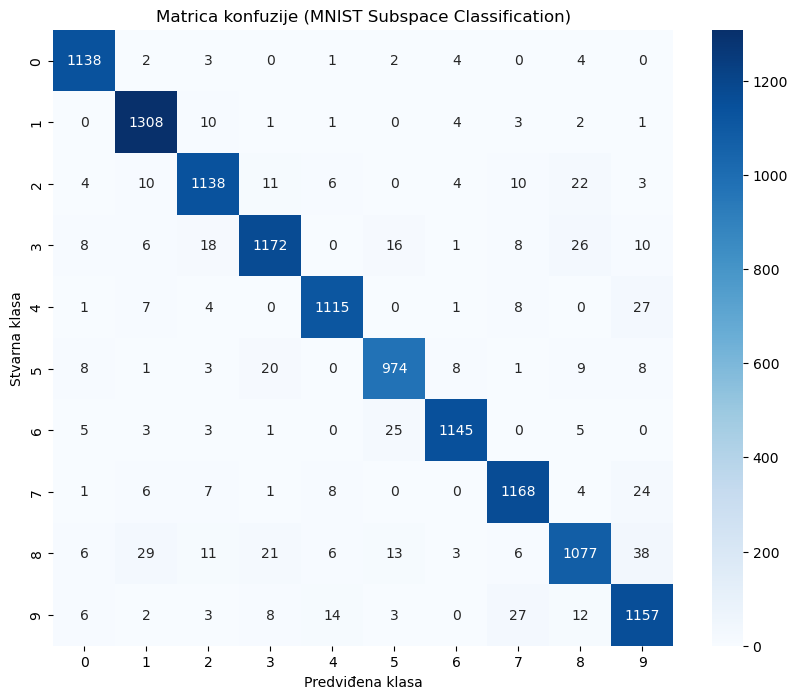

Cifra 0: 98.6% tačnosti
Cifra 1: 98.3% tačnosti
Cifra 2: 94.2% tačnosti
Cifra 3: 92.6% tačnosti
Cifra 4: 95.9% tačnosti
Cifra 5: 94.4% tačnosti
Cifra 6: 96.5% tačnosti
Cifra 7: 95.8% tačnosti
Cifra 8: 89.0% tačnosti
Cifra 9: 93.9% tačnosti


In [105]:
plt.figure(figsize=(10, 8))
sns.heatmap(M, annot=True, fmt='d', cmap='Blues', 
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predviđena klasa')
plt.ylabel('Stvarna klasa')
plt.title('Matrica konfuzije (MNIST Subspace Classification)')
plt.show()

# Ispis procentualne tačnosti po svakoj cifri
procenti_po_cifri = np.diag(M) / np.sum(M, axis=1)
for i, p in enumerate(procenti_po_cifri):
    print(f"Cifra {i}: {p*100:.1f}% tačnosti")

In [83]:
procenti=np.diag(M)/np.sum(M,axis=1)
print(procenti) #procenti dobre klasifikacije po svakoj cifri

[0.98613518 0.98345865 0.94205298 0.92648221 0.95872743 0.94379845
 0.96461668 0.95816243 0.89008264 0.93912338]


In [84]:
print("Najgore klasifikovana cifra:",np.argmin(procenti)) 
print("Najbolje klasifikovana cifra:",np.argmax(procenti))

Najgore klasifikovana cifra: 8
Najbolje klasifikovana cifra: 0


In [85]:
kos_train=np.empty((10,train_idx.size))
for i in range(10):
    pom=A_train-mu_klasa[:,i].reshape(m,1)
    U=baze[i]
    proj=U@(U.T@pom)
    kos_train[i]=np.linalg.norm(proj , axis=0)/np.linalg.norm(pom , axis=0)

trening_klase=np.argmax(kos_train, axis=0)
np.sum(trening_klase==l_train), train_idx.size

(46593, 48000)

In [86]:
np.sum(trening_klase==l_train)/ train_idx.size

0.9706875

Примећујемо сличније резултате квалитета класификације на тренинг и тест подацима.

**Закључак** приказаног експеримента јесте да је за проблеме класификације бољи приступ приказивања класа потпросторима истих димензија, не много великих. На тај начин се избегава претрениравање модела. Такође, постиже се и да се растојања вектора од потпростора мере ортогоналним комплементима истих димензија. Тиме је обезбеђена равноправност мерених растојања.

***

**Пример 10.** Дискриминативна анализа потпростора (SDA)

Приказаћемо још један приступ класификацији заснованој на раду са потпросторима. Поступак је познат као DPCA (Discriminative PCA, Discriminant subspace Analysis или Subspace-based Discriminant Analysis). Идеја иза овог поступка јесте да се сваки од потпростора класа добијених са SVD линеарним трансформацијама пресликају у потпросторе који су више међусобно "линеарно независни". Најпожељније је да су међусобно ортогонални. У наставку описујемо математичке основе и сам поступак SDA. Искористићемо класе описане потпросторима истих димензија из претходног примера.

У претходном примеру (Пример 9) видели смо да се потпростори различитих класа (нпр. цифара 3, 5 и 8) често преклапају. То се дешава зато што стандардни PCA тражи правце који најбоље описују варијансу унутар једне класе, не обазирући се на то колико су ти правци слични правцима друге класе. SDA решава овај проблем тако што тражи нову линеарну трансформацију 
$W$ која ће "изокренути" и "проредити" простор тако да потпростори класа постану што више међусобно ортогонални (независни).

Подсетимо се да трансформација конгруенције симетричних матрица $A=TBT^T$ чува њихову дефинитност (дефиниција 4, радна свеска 27SimetricneMatrice). Овде је $T$ регуларна матрица. У случају да је $T$ мањег ранга од максималног мења се број сопствених вредности једнаких 0, не и знак.

Претпоставимо да класификациони проблем има $k$ класа представљених ортонормираним базама (колоне матрице) $U_i\in\mathcal{M}_{m\times r}$ одговарајућих потпростора. Свака од класа садржи $n_i$ вектора. Користимо две мере описа квалитета линеарне зависности потпростора класа:
1. Мера $S_b$ **унутар-класна матрица расипања** служи за опис блискости елемената унутар самих класа,
$$S_b=\sum_{i\in(k)}U_iU_i^T.$$
Ова матрица је заправо збир матрица пројекција на све потпросторе класа редом. 
Ако се потпростори различитих класа преклапају дуж неког правца, тај правац ће имати велику вредност у $S_b$. 
Наш циљ је да минимизујемо утицај ових праваца, јер они уносе забуну (преклапање) између класа.
1. Мера $S_r$ **међукласна матрица расипања** служи за опис раздвојености елемената између различитих класа.
$$\overline{U_i}=\dfrac1{n_i}\sum_{u\in U_i}u,\qquad\overline{U}=\dfrac1k\sum_{i\in(k)}U_i,\qquad S_r=\sum_{i\in(k)}n_i(\overline{U_i}-\overline{U})(\overline{U_i}-\overline{U})^T.$$
Ова матрица мери колико су центри потпростора класа удаљени једни од других и од општег центра свих података. Наш циљ је да максимизирамо ове вредности како бисмо класе што више размакнули.

Приметимо да су $S_b$ и $S_r$ дате као збир матрица корелација, тј. као збир позитивно семидефинитних симетричних матрица. Самим тим су и $S_b$ и $S_r$ позитивно семидефинитне симетричне матрице.
Добар опис класификационих потпростора требало би да омогући што веће растојање између потпростора различитих класа. To значи што веће сопствене вредности матрице $S_r,$ (што веће истезање потпростора). Осим тога циљ је што мање преклапање потпростора класа. То се огледа кроз што мање сопствене вредности матрице $S_b.$

Сопствене вредности $\lambda$ матрице $S$ могу да се опишу и помоћу тзв. Рејлијевог количника:
$$x^T\ \Big/\quad Sx=\lambda x\quad\Longrightarrow\quad x^TSx=\lambda x^Tx \quad\Longrightarrow\quad
\lambda=\dfrac{x^TSx}{x^Tx}.$$
Отуда се проблем оптималног издвајања потпростора своди на следећу оптимизацију:
$$\lambda=\max_{x\neq\theta}\dfrac{x^TS_rx}{x^TS_bx} .$$

С обзиром да то желимо да урадимо за све сопствене вредности ових матрица, постављени проблем можемо да запишемо у облику 
$$\max_{W}\dfrac{{\rm tr}(W^TS_rW)}{{\rm tr}(W^TS_bW)},$$
где је $W\in\mathcal{M}_{m\times d}.$ Другим речима, тражимо трансформацију $W$ потпростора класа која ће побољшати карактеристике расипања представника класа.

Траг представља суму варијанси дуж свих одабраних праваца. Ово је добра мера укупног расипања. Максимизација овог количника је математички врло погодна јер је траг линеаран оператор.

**Напомена:** Уместо трага матрице, за опис овог оптимизационог проблема користи се и детерминанта
$$\max_{W}\dfrac{{\rm det}(W^TS_rW)}{{\rm det}(W^TS_bW)}.$$
Детерминанта геометријски представља запремину елипсоида расипања.

Претпоставимо да је $x$ један од вектора којим се постиже максимум,
$$S_rx=\lambda_rx,\quad S_bx=\lambda_bx\quad\Longrightarrow\quad S_rx=\dfrac{\lambda_r}{\lambda_b}\lambda_b x
=\lambda S_b x.$$
Једнакост $S_rx=\lambda S_b x$ зовемо проблем уопштених сопствених вредности (Generalized eigenvalue problem). Скалар $\lambda$ и ненула вектор $x$ представљају уопштени сопствени пар за матрице $S_r$ и $S_b.$

**Напомена:** Како матрице $S_r$ и $S_b$ могу да буде семидефинитне, у горњим једнакостима не посматрамо сопствене векторе из језгра матрице $S_b$ $(\lambda_b=0).$ 

Уопштене сопствене векторе $x$ тражимо у пресецима сопствених потпростора две матрице. Уведимо ознаке редуковане спектралне декомпозиције матрице $S_b,$
$$S_b=QDQ^T,\quad Q\in\mathcal{M}_{m\times r},\quad D\in\mathcal{M}_{r\times r},\quad D={\rm diag}(d_0,\dots,d_{r-1}),\ d_i>0.$$ 
Тада је, уз ознаку $T=D^{-1/2}Q^T,\quad D={\rm diag}\big(\sqrt{d_0},\dots,\sqrt{d_{r-1}}\big)$ и $T^+=QD^{1/2},$
$$TT^+=I,\qquad T^+T=QQ^T=P_{\mathcal{R}(Q)}=P_{\mathcal{R}(S_b)}.$$
Због симетричности матрица ортогоналних пројекција важи
$$T^+T=(T^+T)^T=T^T(T^+)^T.$$
С обзиром да је уопштени сопствени вектор $x\in\mathcal{R}(S_b),$ то је $$T^+Tx=T^T(T^+)^Tx=x.$$
Јасно је да је $$S_b=T^+(T^+)^T.$$

Сада проблем уопштених сопствених парова постаје:
\begin{align}
&S_rx=\lambda S_b x\quad&&\Longleftrightarrow\quad S_rx=\lambda T^+(T^+)^Tx
\quad&&\Longrightarrow\quad TS_rx=\lambda TT^+(T^+)^Tx \\
\Longleftrightarrow\quad & TS_rx=\lambda (T^+)^Tx 
\quad&&\Longleftrightarrow\quad TS_rT^T(T^+)^Tx=\lambda (T^+)^Tx
\end{align}
Уведимо смену: $\qquad (T^+)^Tx=v.$
$$\Longleftrightarrow\quad TS_rT^Tv=\lambda  v
\quad\Longleftrightarrow\quad Sv=\lambda v.
$$
Другим речима, решавамо стандардни проблем сопствених вредности за симетричну матрицу: 
$$S=TS_rT^T$$ који нису у њеном језгру. Наиме, сопствена вредност $\lambda=0$ означава сопствену вредност $\lambda_r=0.$ Сопствене вредности једнаке нули не доприносе оптимизационом критеријуму (тј. не утичу на вредност трага), па их можемо занемарити.

За сваки пронађен сопствени вектор $v$ користимо смену $\qquad (T^+)^Tx=v$ за израчунавање $x,$
$$T^T(T^+)^Tx=x\quad \Longrightarrow\quad x=T^Tv.$$

Уколико је $V\in\mathcal{M}_{m\times d}$ матрица ортонормираних сопствених вектора $v$ матрице $S,$ 

In [95]:
# Тренинг
mu_klasa=np.empty((m,10))
for i in range(10):
    idx=l_train==i
    mu_klasa[:,i]=A_train[:,idx].mean(axis=1)
    A_train[:,idx]-=mu_klasa[:,i].reshape(m,1)

r=60
baze=[]
for i in range(10):
    idx=l_train==i
    U,_,_=spl.svd(A_train[:,idx],full_matrices=False)
    baze.append(U[:,:r])

In [96]:
# Izračunavanje unutar-klasne matrice rasipanja (S_w)
Sw = np.zeros((m, m))
for U in baze:
    Sw += U @ U.T 

# Izračunavanje međuklasne matrice (pojednostavljeno preko razlike baza)
M_sve = np.mean(np.array([U @ U.T for U in baze]), axis=0)
Sb = np.zeros((m, m))
for U in baze:
    P = U @ U.T
    Sb += (P - M_sve) @ (P - M_sve).T

# Rešavanje uopštenog problema sopstvenih vrednosti
# Dodajemo malu vrednost na dijagonalu Sw radi numeričke stabilnosti (regularizacija)
eigvals, eigvecs = spl.eigh(Sb, Sw + 1e-4 * np.eye(m))

# Uzimamo k najboljih diskriminativnih pravaca
k = 20
W = eigvecs[:, -k:] 

print("Diskriminativna matrica W je izračunata. Dimenzije:", W.shape)

Diskriminativna matrica W je izračunata. Dimenzije: (784, 20)


In [98]:
# 1. Izračunavanje rastojanja test podataka od svakog potprostora
rastojanja = np.empty((10, A_test.shape[1]))

for i in range(10):
    # Centriranje u odnosu na prosek i-te klase
    pom = A_test - mu_klasa[:, i].reshape(m, 1)
    # Projekcija na bazu i-te klase: P = U @ U.T
    U = baze[i]
    projekcija = U @ (U.T @ pom)
    # Rezidual (greška): rastojanje od tačke do njene projekcije na potprostor
    rastojanja[i] = np.linalg.norm(pom - projekcija, axis=0)

# 2. Predviđanje klase (indeks najmanjeg rastojanja)
test_predikcije = np.argmin(rastojanja, axis=0)

# 3. Izračunavanje ukupne tačnosti
tacnost = np.sum(test_predikcije == l_test) / len(l_test)
print(f"Ukupna tačnost modela: {tacnost*100:.2f}%")

Ukupna tačnost modela: 94.09%


Приказаћемо неколико слика са њиховим стварним и предвиђеним ознакама. Зеленом бојом ћемо означити тачне, а црвеном погрешне класификације.

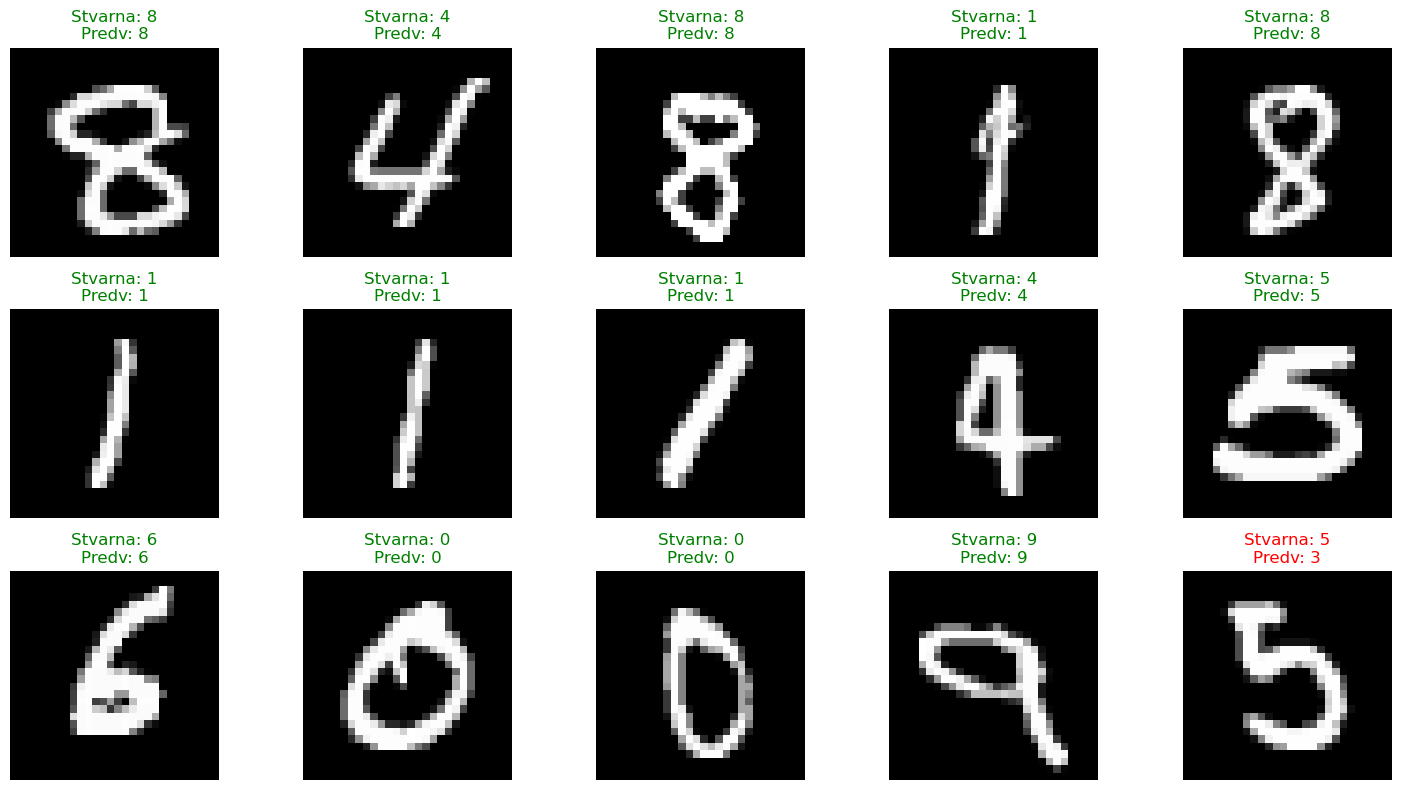

In [99]:
plt.figure(figsize=(15, 8))
# Biramo 15 nasumičnih indeksa iz test skupa
nasumicni_indeksi = rndm.choice(len(l_test), 15)

for i, idx in enumerate(nasumicni_indeksi):
    plt.subplot(3, 5, i + 1)
    slika = A_test[:, idx].reshape(28, 28)
    stvarna = int(l_test[idx])
    predvidjena = int(test_predikcije[idx])
    
    boja = 'green' if stvarna == predvidjena else 'red'
    
    plt.imshow(slika, cmap='gray')
    plt.title(f"Stvarna: {stvarna}\nPredv: {predvidjena}", color=boja)
    plt.axis('off')

plt.tight_layout()

Матрица конфузије (Детаљна анализа грешака)

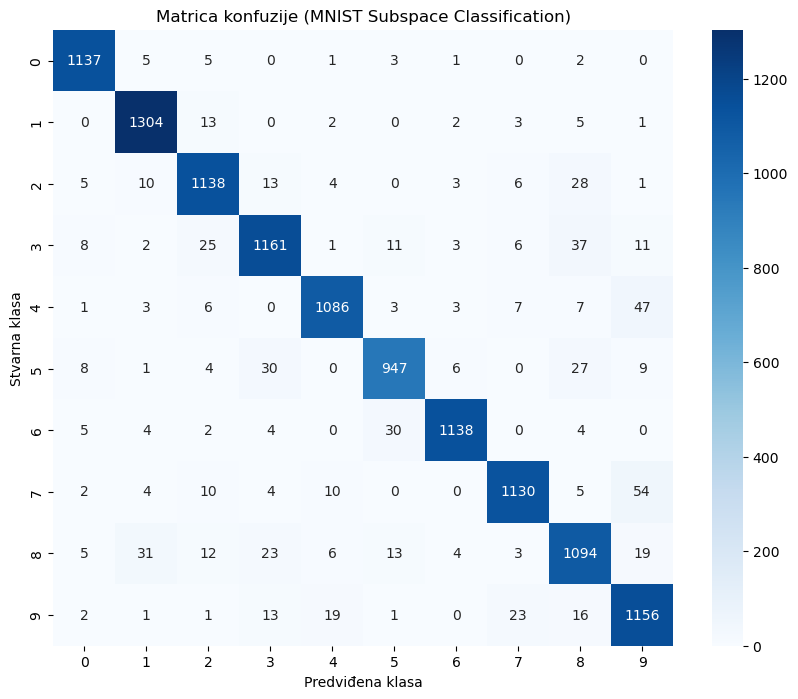

Cifra 0: 98.5% tačnosti
Cifra 1: 98.0% tačnosti
Cifra 2: 94.2% tačnosti
Cifra 3: 91.8% tačnosti
Cifra 4: 93.4% tačnosti
Cifra 5: 91.8% tačnosti
Cifra 6: 95.9% tačnosti
Cifra 7: 92.7% tačnosti
Cifra 8: 90.4% tačnosti
Cifra 9: 93.8% tačnosti


In [100]:
# Kreiranje matrice konfuzije
M = confusion_matrix(l_test, test_predikcije)

plt.figure(figsize=(10, 8))
sns.heatmap(M, annot=True, fmt='d', cmap='Blues', 
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predviđena klasa')
plt.ylabel('Stvarna klasa')
plt.title('Matrica konfuzije (MNIST Subspace Classification)')
plt.show()

# Ispis procentualne tačnosti po svakoj cifri
procenti_po_cifri = np.diag(M) / np.sum(M, axis=1)
for i, p in enumerate(procenti_po_cifri):
    print(f"Cifra {i}: {p*100:.1f}% tačnosti")

Mодел најбоље препознаје "1" и "0" јер су њихови потпростори врло специфични и добро раздвојени. Ако постоје велики бројеви ван дијагонале, то значи да су потпростори тих двеју цифара "блиски".

***

### Нелинеарна редукција: Kernel PCA

Када подаци нису линеарно сепарабилни (нпр. подаци распоређени у облику концентричних кругова или „месеца“), стандардни PCA неће дати добре резултате. Стандардни PCA је ограничена на проналажење линеарних зависности. Ако подаци леже на нелинеарној структури (нпр. једна класа је унутар друге), линеарна пројекција ће их потпуно измешати. Kernel PCA користи „kernel trick“ за (имплицитно) мапирање података у високодимензионални простор (Feature Space) где они постају линеарно сепарабилни.

Најчешће се користи RBF (Radial Basis Function) кернел:
$$
K(x,y) = \exp\!\left(-\gamma \,\lVert x - y \rVert^{2}\right).
$$
Параметар $\gamma$ контролише „ширину“ утицаја појединачне тачке. Веће $\gamma$ значи да кернел „гледа“ само врло блиске суседе.

**Пример 11.** Класификација нелинеарних података (Кругови)

Показаћемо како стандардни PCA не успева да раздвоји податке распоређене у облику концентричних кругова, док Kernel PCA омогућава савршену класификацију чак и ако податке сведемо на само једну димензију.

In [108]:
from sklearn.decomposition import KernelPCA
from sklearn.datasets import make_circles
from sklearn.linear_model import LogisticRegression

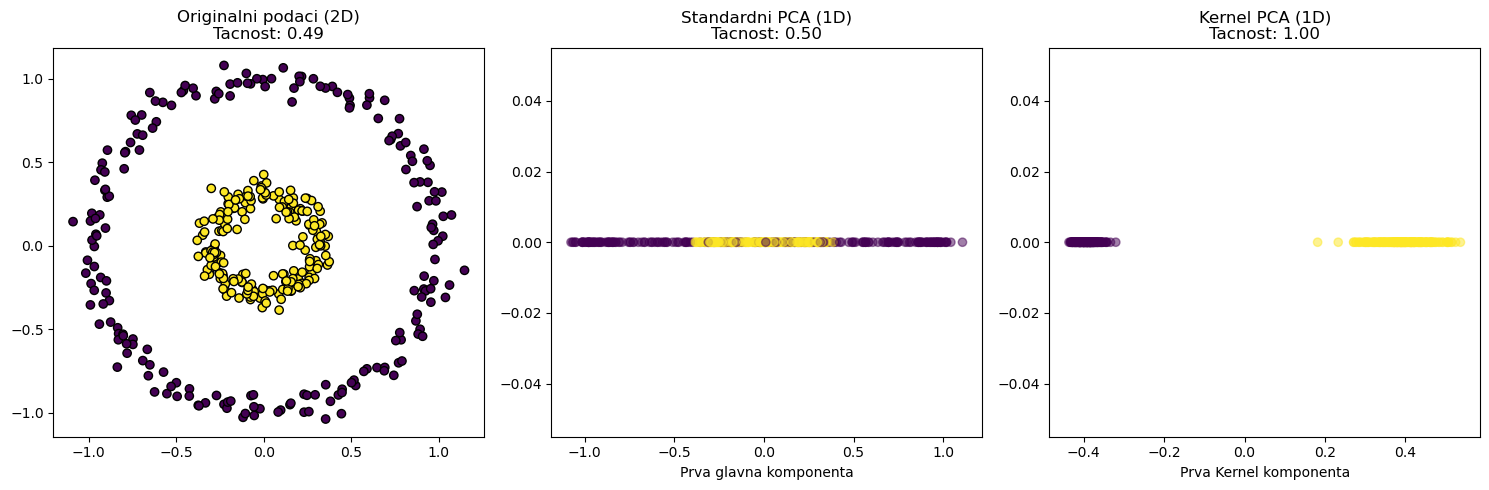

In [114]:
# 1. Generisanje podataka: Unutrašnji i spoljašnji krug
X, y = make_circles(n_samples=400, factor=.3, noise=.05, random_state=42)

# 2. Primena Standardnog PCA (redukcija na 1D)
pca = PCA(n_components=1)
X_pca = pca.fit_transform(X)

# 3. Primena Kernel PCA sa RBF kernelom (redukcija na 1D)
kpca = KernelPCA(n_components=1, kernel='rbf', gamma=2.5)
X_kpca = kpca.fit_transform(X)

# 4. Evaluacija: Pokušaj klasifikacije linearnim modelom (Logistička regresija)
# Na originalnim podacima (2D)
lr_orig = LogisticRegression().fit(X, y)
# Na 1D projekciji običnog PCA
lr_pca = LogisticRegression().fit(X_pca, y)
# Na 1D projekciji Kernel PCA
lr_kpca = LogisticRegression().fit(X_kpca, y)

# Prikaz rezultata
plt.figure(figsize=(15, 5))

# Originalni podaci
plt.subplot(1, 3, 1)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolors='k')
plt.title(f"Originalni podaci (2D)\nTacnost: {lr_orig.score(X, y):.2f}")

# Standardni PCA
plt.subplot(1, 3, 2)
plt.scatter(X_pca, np.zeros_like(X_pca), c=y, cmap='viridis', alpha=0.5)
plt.title(f"Standardni PCA (1D)\nTacnost: {lr_pca.score(X_pca, y):.2f}")
plt.xlabel("Prva glavna komponenta")

# Kernel PCA
plt.subplot(1, 3, 3)
plt.scatter(X_kpca, np.zeros_like(X_kpca), c=y, cmap='viridis', alpha=0.5)
plt.title(f"Kernel PCA (1D)\nTacnost: {lr_kpca.score(X_kpca, y):.2f}")
plt.xlabel("Prva Kernel komponenta")

plt.tight_layout()

#### Линеарна нераздвојивост.  
На првом графику ниједна права линија не може раздвојити жуте од љубичастих тачака.  
Зато чак и у 2D простору линеарна логистичка регресија има тачност од приближно $50\%$.

#### Неуспех обичног PCA.  
Када PCA пројектује концентричне кругове на једну димензију (средњи график),  
тачке се потпуно измешају.  
Информација о томе шта је „унутра“, а шта „споља“, у потпуности је изгубљена.

#### Успех Kernel PCA.
RBF кернел ефикасно мери растојање тачака од центра.  
На десном графику видимо да су све тачке унутрашњег круга завршиле на једној страни осе,  
а тачке спољашњег круга на другој.  
Један једноставан праг на овој линији сада савршено раздваја класе.

Променићемо вредност параметра $\Gamma$ како би видели његове ефекте на резултат.

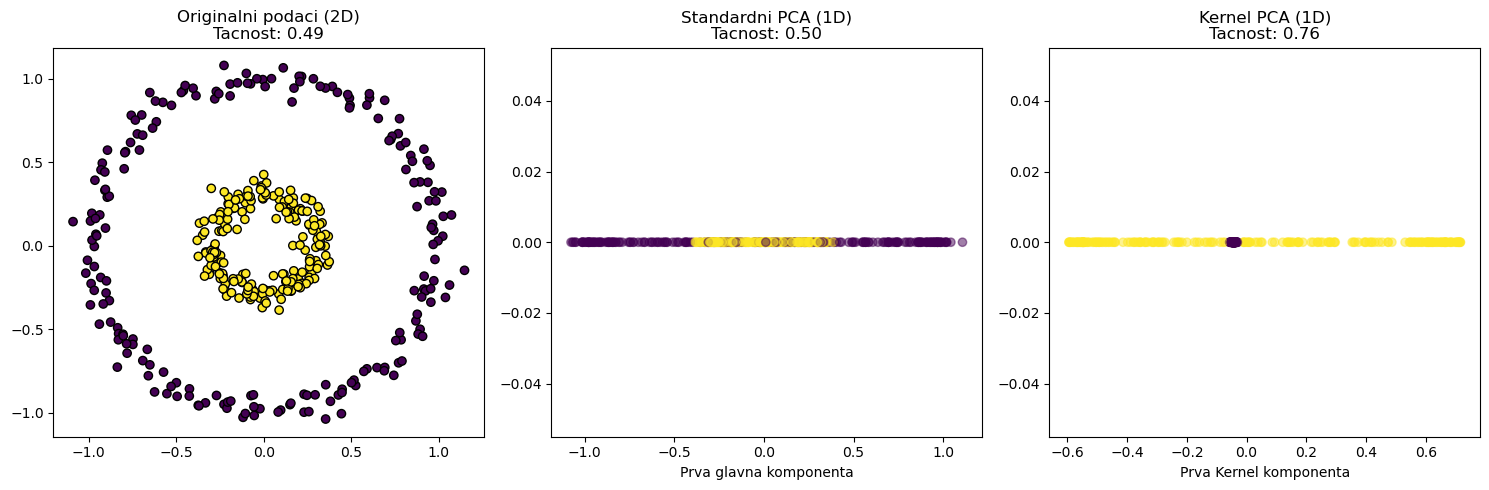

In [115]:
# 1. Generisanje podataka: Unutrašnji i spoljašnji krug
X, y = make_circles(n_samples=400, factor=.3, noise=.05, random_state=42)

# 2. Primena Standardnog PCA (redukcija na 1D)
pca = PCA(n_components=1)
X_pca = pca.fit_transform(X)

# 3. Primena Kernel PCA sa RBF kernelom (redukcija na 1D)
kpca = KernelPCA(n_components=1, kernel='rbf', gamma=10.5)
X_kpca = kpca.fit_transform(X)

# 4. Evaluacija: Pokušaj klasifikacije linearnim modelom (Logistička regresija)
# Na originalnim podacima (2D)
lr_orig = LogisticRegression().fit(X, y)
# Na 1D projekciji običnog PCA
lr_pca = LogisticRegression().fit(X_pca, y)
# Na 1D projekciji Kernel PCA
lr_kpca = LogisticRegression().fit(X_kpca, y)

# Prikaz rezultata
plt.figure(figsize=(15, 5))

# Originalni podaci
plt.subplot(1, 3, 1)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolors='k')
plt.title(f"Originalni podaci (2D)\nTacnost: {lr_orig.score(X, y):.2f}")

# Standardni PCA
plt.subplot(1, 3, 2)
plt.scatter(X_pca, np.zeros_like(X_pca), c=y, cmap='viridis', alpha=0.5)
plt.title(f"Standardni PCA (1D)\nTacnost: {lr_pca.score(X_pca, y):.2f}")
plt.xlabel("Prva glavna komponenta")

# Kernel PCA
plt.subplot(1, 3, 3)
plt.scatter(X_kpca, np.zeros_like(X_kpca), c=y, cmap='viridis', alpha=0.5)
plt.title(f"Kernel PCA (1D)\nTacnost: {lr_kpca.score(X_kpca, y):.2f}")
plt.xlabel("Prva Kernel komponenta")

plt.tight_layout()

„Залутала“ љубичаста тачка међу жутима (или обрнуто) појављује се из два главна разлога који су кључни за разумевање машинског учења:

1. Шум у подацима (noise = 0.05).  
У коду смо генерисали податке са параметром $ \text{noise} = 0.05 $.  
То значи да неке тачке из спољашњег круга могу бити потиснуте ка унутра,  
а неке из унутрашњег ка споља.  
Ако је тачка у оригиналном 2D простору због шума завршила „на погрешној територији“,  
Kernel PCA ће је тако и мапирати.  
Математика не може да исправи тачку која је физички преблизу другој класи.

2. Осетљивост на параметар $\gamma$.  
Параметар $\gamma$ одређује колико „далеко“ сеже утицај сваке тачке.
- Ако је $\gamma$ превелико (нпр. 15 или 20), модел постаје превише осетљив  
    и почиње да „памти“ сваку тачку појединачно (overfitting).  
    Тада и најмањи шум прави велике дисконтинуитете.
- Ако је $\gamma$ премало, модел неће успети да препозна кружну структуру.

Да бисте били сигурни да ли је у питању само једна тачка или веће преклапање, можемо додати мало "шума" по ипсилон оси (тзв. jitter) како се тачке не би преклапале на истој линији. Такође, пробајте да смањите gamma на 1 или 2 за стабилније резултате.
Ево модификованог дела за приказ Kernel PCA који ће разјаснити ситуацију.

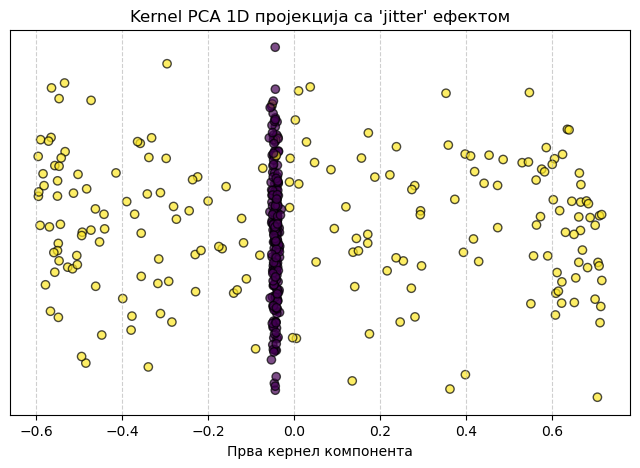

In [117]:
# Kernel PCA са мањим гама параметром за бољу генерализацију
kpca = KernelPCA(n_components=1, kernel='rbf', gamma=10.5) 
X_kpca = kpca.fit_transform(X)

plt.figure(figsize=(8, 5))

# Додајемо мали случајни шум на y-осу да бисмо видели све тачке (jitter)
jitter = np.random.normal(0, 0.02, size=X_kpca.shape[0])

plt.scatter(X_kpca[:, 0], jitter, c=y, cmap='viridis', alpha=0.7, edgecolors='k')

plt.title("Kernel PCA 1D пројекција са 'jitter' ефектом")
plt.xlabel("Прва кернел компонента")
plt.yticks([]) # Сакривамо y-осу јер је вештачка
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

RBF кернел мери сличност.

Тачке унутрашњег круга су релативно близу једна другој, па имају велику међусобну 
сличност. Kernel PCA их зато „збија“ у један густ кластер.

Тачке спољашњег круга су далеко једна од друге (оне на супротним странама прстена 
су најдаље могуће). Међутим, све оне имају сличну (малу) сличност са унутрашњим кругом.

У 1D пројекцији, алгоритам је мапирао „центар“ података (љубичасти круг) у средину 
нове осе, а „периферију“ (жути круг) на крајеве. Пошто спољашњи круг окружује унутрашњи 
у свим правцима, његове тачке се „преклапају“ на ивицама када се пројектују на само једну линију.

**Trade-off (компромис):**

#### Чисти подаци
Ако поставите $ \text{noise} = 0 $ у \texttt{make\_circles}, раздвајање ће бити савршено.

#### Реални подаци
У стварности, подаци су увек „прљави“. Чак и најбољи алгоритми (попут Kernel PCA) имају границу до које могу да раздвоје класе које се природно преклапају.

#### Хиперпараметри.
Избор параметра $\gamma$ је уметност. У пракси се користи Grid Search да се пронађе најбоља вредност.

#### Outlier-и
Ако и даље видите љубичасту тачку дубоко у жутој територији, то је outlier (екстремна вредност).  
У вештачкој интелигенцији често је боље дозволити једну такву грешку него превише
„искривити“ модел да би је обухватио, јер то води у лошу предикцију на новим подацима.

Да бисте добили ситуацију где су све жуте тачке са једне стране, а све љубичасте са друге, морамо подесити 
$\gamma$  тако да кернел „види“ структуру целог круга.

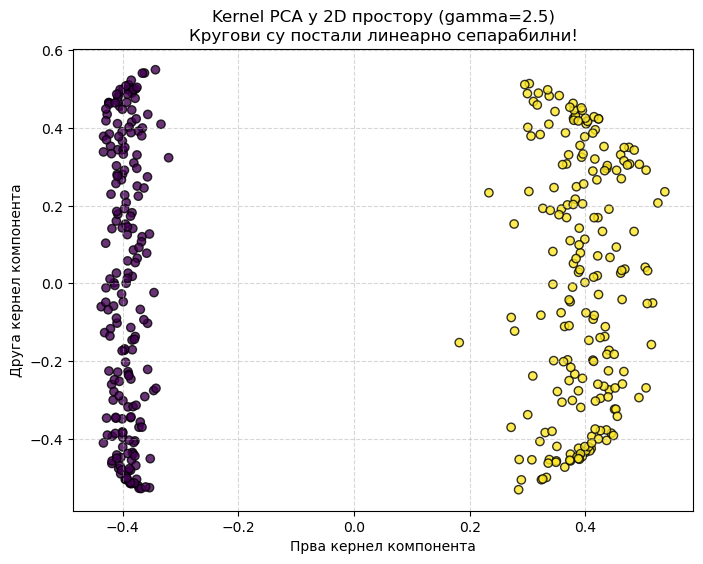

In [118]:
# Поставите gamma тачно на 2.5 или 3.0
# То је често граница где структура круга постаје линеарно раздвојива
kpca_final = KernelPCA(n_components=2, kernel='rbf', gamma=2.5)
X_kpca_final = kpca_final.fit_transform(X)

# Хајде да погледамо прве ДВЕ компоненте, ту се магија најбоље види
plt.figure(figsize=(8, 6))
plt.scatter(X_kpca_final[:, 0], X_kpca_final[:, 1], c=y, cmap='viridis', edgecolors='k', alpha=0.8)
plt.title("Kernel PCA у 2D простору (gamma=2.5)\nКругови су постали линеарно сепарабилни!")
plt.xlabel("Прва кернел компонента")
plt.ylabel("Друга кернел компонента")
plt.grid(True, linestyle='--', alpha=0.5)

Најбољи начин да се стекне интуитивни увид како Kernel PCA мења топологију простора је интеактивни график. Користићемо ipywidgets за креирање слајдера који у реалном времену мења параметар $\gamma$.

Интерактивни приказ ће имати два дела:
- Оригинални подаци (2D).
- Пројекција на прву кернел компоненту (1D)} — овде ћемо додати 
    мали „jitter“ (шум по $y$-оси) како би се јасно видело где се тачке преклапају,
    а где раздвајају.

In [112]:
from ipywidgets import interact, FloatSlider

In [113]:
# 1. Generisanje podataka (fiksno da bi samo gamma uticala na promenu)
X, y = make_circles(n_samples=400, factor=.3, noise=.05, random_state=42)

def plot_kpca(gamma_val):
    # Izračunavanje Kernel PCA sa trenutnim gamma
    kpca = KernelPCA(n_components=1, kernel='rbf', gamma=gamma_val)
    X_kpca = kpca.fit_transform(X)
    
    # Kreiranje figure
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    
    # Levi plot: Originalni 2D prostor
    ax1.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolors='k', alpha=0.7)
    ax1.set_title("Оригинални подаци (2D)")
    ax1.set_xlabel("x1")
    ax1.set_ylabel("x2")
    ax1.grid(True, linestyle='--', alpha=0.5)
    
    # Desni plot: 1D Projekcija sa jitter-om (da se vidi gustina)
    # Dodajemo mali vertikalni šum (jitter) samo radi vizuelizacije preklapanja
    jitter = np.random.normal(0, 0.01, size=X_kpca.shape[0])
    
    ax2.scatter(X_kpca[:, 0], jitter, c=y, cmap='viridis', edgecolors='k', alpha=0.6)
    ax2.set_title(f"Kernel PCA 1D пројекција (gamma = {gamma_val:.2f})")
    ax2.set_xlabel("Прва кернел компонента")
    ax2.set_yticks([]) # Sakrivamo y-osu jer je jitter veštački
    ax2.set_ylim(-0.1, 0.1)
    
    # Dodajemo vertikalnu liniju na x=0 radi orijentacije
    ax2.axvline(0, color='red', linestyle=':', alpha=0.5)
    ax2.grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

# Kreiranje interaktivnog slajdera
# Opseg od 0.01 (linearno mešanje) do 20.0 (lokalni šum/overfitting)
interact(plot_kpca, gamma_val=FloatSlider(value=1.0, min=0.01, max=20.0, step=0.1, description='Gamma:'));

interactive(children=(FloatSlider(value=1.0, description='Gamma:', max=20.0, min=0.01), Output()), _dom_classe…

**Шта да тражите померањем слајдера:**

**Мале вредности** ($\Gamma < 0.5$):
Љубичасте и жуте тачке су потпуно измешане. Ово је зона underfitting-а. Кернел је „преширок“ и не види разлику између кругова.

**Свит спот** ($\Gamma \approx 1.0$–$4.0$):  
Љубичасте тачке се издвајају у једну групу, а жуте у другу. У идеалном случају, могла би се повући једна вертикална линија која их раздваја.

**Ефекат „сендвича“** ($\Gamma > 7.0$):  
Љубичасте тачке се групишу у средини, а жуте их окружују са обе стране осе. Кернел постаје „ужи“ и препознаје центар као специфичан, док спољашњи круг и даље види као периферију која је подједнако различита од центра.

**Екстремне вредности** ($\Gamma > 15.0$):  
Тачке почињу да се јако збијају или постају хаотично распоређене. Ово је overfitting — кернел види само најближе суседе и губи глобалну структуру кругова.

**Поука за крај одељка**

Овај „неуспех” са мешањем тачака је заправо највреднији део лекције.

**„Клетва и благослов хиперпараметара.”**

Кернел PCA нам показује да математички модел може бити моћан само онолико колико смо прецизни у његовом подешавању.
- $\gamma$ \textbf{превелико}: видимо само шум (overfitting).
- $\gamma$ \textbf{премало}: губимо структуру и враћамо се на линеарно мешање (underfitting).
- $\gamma$ \textbf{погођено}: нелинеаран свет постаје линеарно регалан.

Ово је суштина вештачке интелигенције - проналажење праве трансформације простора у којој тежак проблем постаје очигледан.

***

Сингуларна декомпозиција (SVD) је швајцарски нож линеарне алгебре у вештачкој интелигенцији.  
Кроз ову свеску смо прошли пут од:
- геометријских изазова високе димензионалности,
- апроксимације матрица (компресије) као начина за ефикасно чување података,
- PCA анализе као статистичког алата за проналажење кључних карактеристика,
- класификације потпросторима и напредних кернел метода за нелинеарне проблеме.

Разумевање SVD-а није само теоријска вежба; tо је основа за модерне архитектуре попут трансформера (Attention механизам),  генеративних модела и система за препоручивање.

***